# Part 1 — choose at most 10 factors, then test the long-only book

This notebook answers one question from `03_mlfactor_long_only_project.ipynb`:

> Perform feature subset selection where you choose 10 or less features. Your feature selection process should involve data analysis and/or machine learning techniques. Conduct some analysis as to whether restricting to your feature subset seems to be improving strategy performance.

The rules for that answer are locked in `01_plan.md`. This notebook follows that file. A column enters the submitted list only when the training months support it. The test file is used once, after the list has been written to disk, to see what the same trading rule does with all 20 columns and with the shorter list.

What "better" means here is the long-only book, not a higher in-sample R². Each month the model ranks the stocks that exist that month. The book holds the top quintile in equal weight and earns those stocks' next-month returns. The same model, the same penalty, and the same quintile are run on both column sets. The column set is the only difference.

Later assignment items stay out of this notebook: the four model families, `GridSearchCV`, a second non-ML strategy, and the final model choice. The equal-weight average of every name in the month is drawn as a reference line so the curves have a baseline. It is the assignment's equally weighted market, because the files have no market-cap column.

## Rules that keep the comparison honest

- Sort by `date`, then `stock_id`, at load. `date` and `stock_id` are never features.
- `select_features` sees only the frame it is given. The yearly lists see only snapshots before the year they trade.
- `subset_final` is chosen on all 120 training snapshots and written to `subset_final.csv` before any test-set model, strategy metric, or plot.
- The test backtest is one pass. The capped-return view and the turnover haircut are views of that same pass. They do not create a new feature list.
- `random_state=0` wherever a model accepts it.
- A high feature value means the raw characteristic is high relative to the other stocks that month. The model is allowed to learn a negative sign. No column is flipped by hand.

## Map

1. Load the panel and check the calendar.
2. Name the columns, with the uncertain names marked.
3. Show which columns are the same economic idea measured more than once.
4. Measure each column alone, month by month, and show how much of the squared return sits in a few extreme rows.
5. Build `subset_final` with time-ordered lasso frequency, within-month permutation, and a weak information-coefficient term.
6. Rebuild the list once a year inside 2005–2009, always on earlier months, and trade it with ridge.
7. Freeze the list.
8. Run one test backtest, January 2010 through December 2018.
9. Apply the decision rule that was written before that backtest.


## The code that implements the plan

The next cell is the whole method: the fit target, the month folds, the lasso and the permutation, the score, the greedy list, the ridge book, and the performance formulas. Read it as the contract from `01_plan.md` sections 6–8 written in Python. The cells after it run that contract one piece at a time and say what each table is for.

Two readings of details the plan left unspecified, both fixed before the test pass:

- A month with a constant prediction has an undefined Spearman correlation. That month does not vote in the alpha's average. If every inner month is undefined, the largest alpha on the grid is used.
- The first month of a backtest has one-way turnover of 0, because there is no previous book. The reported average turnover skips that month. The 10 bp haircut uses the same series, so the first month is unpenalized.
- Each fold's permutation shuffle starts from `RandomState(0)`. A fold is therefore a function of its own months. Identical folds are reused rather than refit. The reuse does not look at later months.
- Hit rate is the fraction of months whose Spearman IC is strictly positive.
- An undefined permutation drop is stored as 0, so it fails the `perm_drop > 0` gate and sits at the bottom of a min-max only when every drop is undefined.

The decision rule, also fixed before the test pass. Apply the first matching label:

1. **No clear improvement** if the test Ridge Sharpe gap and the walk-forward Ridge Sharpe gap have different signs (zero disagrees with a nonzero gap), or the Sharpe ranking flips after capping each stock's return at 100%, or the median recall of the five yearly lists against `subset_final` is below 0.50.
2. **Simplification with similar performance** if the absolute test Sharpe gap is under 0.05 and the absolute annualized-return gap is under 1 percentage point.
3. **Improvement** if the subset leads on test Sharpe, on the test paired mean return, on walk-forward Sharpe, and on the walk-forward paired mean.
4. Otherwise **no clear improvement**.

Recall for a yearly list is the share of its names that also sit in `subset_final`. The median of those five recalls is the stability number. The 10 bp haircut is reported beside this rule and does not change the label. The forest is a second opinion and does not change the label.


In [1]:
"""Part 1 feature selection. Locked to 01_plan.md. Train rows only."""

from __future__ import annotations

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.ensemble import RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

ROOT = Path(
    "/home/sweethoney/Documents/MFM/Semester5_Sept_Dec_2026/DataScience"
    "/11_mlfactor_long_only_project_2026"
)
HERE = ROOT / "part1_feature_selection"
TRAIN_PATH = ROOT / "mlfactor_long_only_train.csv"
TEST_PATH = ROOT / "mlfactor_long_only_test.csv"

# Section 6 of the plan. These values are the method, not a search.
MIN_TRAIN = 48
VAL_SIZE = 12
INNER_MONTHS = 12
ALPHAS = np.logspace(-5, -2, 16)
ALPHA_BAND = 0.002
COEF_EPS = 1e-8
CORR_GATE = 0.80
MAX_FEATURES = 10
MIN_LIST = 3
N_PERM = 5
PERM_SEED = 0
RIDGE_ALPHA = 1.0
COST_PER_TURNOVER = 0.0010
RETURN_CAP = 1.0
NW_LAG = 3
QUINTILE = 0.80
SCORE_WEIGHTS = (0.40, 0.40, 0.20)
UNSTABLE_RECALL = 0.50

# Filled by the notebook before select_features runs. A fold is a pure
# function of its months, so later yearly origins reuse an identical fit.
FOLD_CACHE: dict = {}

ID_COLS = ("date", "stock_id")
TARGET = "R1M_Usd"

EXPECTED = {
    "train_rows": 140_739,
    "test_rows": 127_740,
    "train_snapshots": 120,
    "test_snapshots": 108,
    "train_start": "1999-12-31",
    "train_end": "2009-11-30",
    "test_start": "2009-12-31",
    "test_end": "2018-11-30",
}

ORIGIN_LAST_SEEN = {
    60: "2004-11-30",
    72: "2005-11-30",
    84: "2006-11-30",
    96: "2007-11-30",
    108: "2008-11-30",
}

GLOSSARY = [
    ("Ocf_Toa", "Operating cash flow / assets", "Medium. Near Ocf_Ta in name; the correlation decides whether they are duplicates."),
    ("Ocf_Ta", "Operating cash flow / assets, second coding", "Medium. Kept separate from Ocf_Toa unless |correlation| reaches 0.80."),
    ("Ocf_Ce", "Operating cash flow / common equity, or cash earnings", "Low. The score does not depend on this reading."),
    ("Ocf_Tbv", "Operating cash flow / tangible book", "Medium."),
    ("Fcf_Tbv", "Free cash flow / tangible book", "Medium. Tightly tied to Ocf_Tbv in the training correlations."),
    ("Fcf_Yld", "Free-cash-flow yield", "High."),
    ("Div_Yld", "Dividend yield", "High."),
    ("Bb_Yld", "Buyback yield", "Medium."),
    ("Netdebtyield", "A net-debt yield or a related valuation spread", "Low."),
    ("Ev_Ebitda", "Enterprise value / EBITDA", "High."),
    ("Tev_Less_Mktcap", "Enterprise value minus market cap, ranked", "Medium. Economically close to net debt."),
    ("Tot_Debt_Rev", "Total debt / revenue", "High."),
    ("Net_Debt", "Net debt, ranked across stocks that month", "Medium."),
    ("Debtequity", "Debt / equity", "High."),
    ("Total_Debt_Capital", "Debt / total capital", "High."),
    ("Total_Liabilities_Total_Assets", "Liabilities / assets", "High."),
    ("Share_Turn_3M", "Share turnover, 3 months", "High."),
    ("Share_Turn_6M", "Share turnover, 6 months", "High."),
    ("Share_Turn_12M", "Share turnover, 12 months", "High."),
    ("Capex_Sales", "Capex / sales", "High."),
]

FAMILIES = {
    "Ocf_Toa": "cash flow",
    "Ocf_Ta": "cash flow",
    "Ocf_Ce": "cash flow",
    "Ocf_Tbv": "cash flow over tangible book",
    "Fcf_Tbv": "cash flow over tangible book",
    "Fcf_Yld": "cash-flow yield",
    "Div_Yld": "dividend yield",
    "Bb_Yld": "buyback yield",
    "Netdebtyield": "net-debt yield",
    "Ev_Ebitda": "valuation multiple",
    "Tev_Less_Mktcap": "enterprise value minus market cap",
    "Tot_Debt_Rev": "leverage",
    "Net_Debt": "leverage",
    "Debtequity": "leverage",
    "Total_Debt_Capital": "leverage",
    "Total_Liabilities_Total_Assets": "leverage",
    "Share_Turn_3M": "share turnover",
    "Share_Turn_6M": "share turnover",
    "Share_Turn_12M": "share turnover",
    "Capex_Sales": "investment",
}


def load_panel(path: Path) -> pd.DataFrame:
    """Sort so each month is one contiguous block. Date and stock id stay out of X."""
    frame = pd.read_csv(path, parse_dates=["date"])
    frame = frame.sort_values(["date", "stock_id"]).reset_index(drop=True)
    return frame


def feature_columns(frame: pd.DataFrame) -> list[str]:
    skip = set(ID_COLS) | {TARGET}
    cols = [c for c in frame.columns if c not in skip]
    if len(cols) != 20:
        raise RuntimeError(f"expected 20 factor columns, found {cols}")
    return cols


def stamp(value) -> str:
    return pd.Timestamp(value).strftime("%Y-%m-%d")


def iter_slices(dates):
    """Yield [start, end) index pairs. `dates` must already be sorted."""
    dates = np.asarray(dates)
    n = len(dates)
    start = 0
    while start < n:
        end = start + 1
        current = dates[start]
        while end < n and dates[end] == current:
            end += 1
        yield start, end
        start = end


def month_bounds(dates):
    """Ordered month keys and the row span of each month."""
    order = []
    bounds = {}
    for start, end in iter_slices(dates):
        key = stamp(dates[start])
        order.append(key)
        bounds[key] = (start, end)
    return order, bounds


def y_fit_array(y, dates) -> np.ndarray:
    """Within each month, clip to the 1st/99th percentile, then subtract the median.

    The thresholds and the median use only the rows passed in. Call this on the
    fitting sample, not on a later month you are about to score with raw returns.
    """
    y = np.asarray(y, dtype=float)
    out = np.empty(len(y), dtype=float)
    for start, end in iter_slices(dates):
        block = y[start:end]
        lo, hi = np.quantile(block, [0.01, 0.99])
        clipped = np.clip(block, lo, hi)
        out[start:end] = clipped - np.median(clipped)
    return out


def spearman(a, b) -> float:
    """Pearson correlation of average ranks. Undefined when either side is constant."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if np.unique(a).size < 2 or np.unique(b).size < 2:
        return np.nan
    ra = rankdata(a, method="average")
    rb = rankdata(b, method="average")
    ra = ra - ra.mean()
    rb = rb - rb.mean()
    denom = np.sqrt(np.dot(ra, ra) * np.dot(rb, rb))
    if denom == 0:
        return np.nan
    return float(np.dot(ra, rb) / denom)


def mean_monthly_spearman(pred, y, dates):
    vals = [spearman(pred[s:e], y[s:e]) for s, e in iter_slices(dates)]
    arr = np.asarray(vals, dtype=float)
    if not np.isfinite(arr).any():
        return np.nan, arr
    return float(np.nanmean(arr)), arr


def shuffle_within(col, dates, rng) -> np.ndarray:
    """Permute one column inside each month. Stocks do not cross months."""
    out = np.array(col, copy=True)
    for start, end in iter_slices(dates):
        out[start:end] = rng.permutation(out[start:end])
    return out


def minmax(values) -> np.ndarray:
    arr = np.asarray(values, dtype=float)
    lo = np.min(arr)
    hi = np.max(arr)
    if not np.isfinite(lo) or not np.isfinite(hi) or hi == lo:
        return np.zeros(len(arr), dtype=float)
    return (arr - lo) / (hi - lo)


def earned_month(snapshot_dates):
    """Snapshot date -> the month-end when R1M_Usd is earned (the next month)."""
    periods = pd.DatetimeIndex(pd.to_datetime(snapshot_dates)).to_period("M")
    return (periods + 1).to_timestamp("M")


def choose_alpha(alphas, scores):
    """Largest alpha among scores within ALPHA_BAND of the best finite score.

    A flat path then prefers the sparser model. If every score is undefined,
    the largest alpha on the grid is the defined answer.
    """
    alphas = np.asarray(alphas, dtype=float)
    scores = np.asarray(scores, dtype=float)
    finite = np.isfinite(scores)
    if not finite.any():
        return float(alphas[-1]), np.nan, np.nan, 0
    best = float(np.max(scores[finite]))
    band = finite & (scores >= best - ALPHA_BAND)
    chosen = float(np.max(alphas[band]))
    span = float(np.max(scores[finite]) - np.min(scores[finite]))
    return chosen, best, span, int(band.sum())


def fit_lasso(x_scaled, y, alpha):
    model = Lasso(alpha=float(alpha), max_iter=20000)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(x_scaled, y)
    n_warn = sum(issubclass(item.category, ConvergenceWarning) for item in caught)
    return model, n_warn


def _forest():
    return RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=400,
        max_features="sqrt",
        random_state=0,
        n_jobs=-1,
    )


def _xgb():
    return XGBRegressor(
        n_estimators=100,
        max_depth=2,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=0,
        n_jobs=-1,
        tree_method="hist",
        verbosity=0,
    )


def evaluate_fold(x, y, dates, train_end, val_end, features):
    """One expanding fold. Validation rows are [train_end, val_end)."""
    x_train = x[:train_end]
    y_train_raw = y[:train_end]
    d_train = dates[:train_end]
    y_train = y_fit_array(y_train_raw, d_train)

    # Last 12 training months are the inner block. They stay inside the outer train.
    order, bounds = month_bounds(d_train)
    if len(order) < INNER_MONTHS + 1:
        raise RuntimeError("outer train is too short for a 12-month inner block")
    inner_val_start = bounds[order[-INNER_MONTHS]][0]
    x_inner_fit = x_train[:inner_val_start]
    y_inner_fit = y_fit_array(y_train_raw[:inner_val_start], d_train[:inner_val_start])
    x_inner_val = x_train[inner_val_start:]
    y_inner_raw = y_train_raw[inner_val_start:]
    d_inner_val = d_train[inner_val_start:]
    y_inner_fit_target = y_fit_array(y_inner_raw, d_inner_val)

    scaler_inner = StandardScaler().fit(x_inner_fit)
    x_inner_fit_s = scaler_inner.transform(x_inner_fit)
    x_inner_val_s = scaler_inner.transform(x_inner_val)

    spearman_scores = []
    mse_scores = []
    warn_count = 0
    for alpha in ALPHAS:
        model, n_warn = fit_lasso(x_inner_fit_s, y_inner_fit, alpha)
        warn_count += n_warn
        pred = model.predict(x_inner_val_s)
        sp, _ = mean_monthly_spearman(pred, y_inner_raw, d_inner_val)
        spearman_scores.append(sp)
        mse_scores.append(-float(np.mean((pred - y_inner_fit_target) ** 2)))

    alpha_sp, best_sp, span_sp, n_band_sp = choose_alpha(ALPHAS, spearman_scores)
    alpha_mse, best_mse, span_mse, n_band_mse = choose_alpha(ALPHAS, mse_scores)

    scaler_outer = StandardScaler().fit(x_train)
    x_train_s = scaler_outer.transform(x_train)
    model_sp, n_warn = fit_lasso(x_train_s, y_train, alpha_sp)
    warn_count += n_warn
    model_mse, n_warn = fit_lasso(x_train_s, y_train, alpha_mse)
    warn_count += n_warn
    coef = model_sp.coef_.astype(float).copy()
    coef_mse = model_mse.coef_.astype(float).copy()

    x_val = x[train_end:val_end]
    y_val = y[train_end:val_end]
    d_val = dates[train_end:val_end]
    forest = _forest()
    forest.fit(x_train, y_train)
    base_pred = forest.predict(x_val)
    base_sp, _ = mean_monthly_spearman(base_pred, y_val, d_val)
    rng = np.random.RandomState(PERM_SEED)
    perm = np.zeros(x.shape[1], dtype=float)
    for j in range(x.shape[1]):
        drops = []
        for _ in range(N_PERM):
            shuffled = x_val.copy()
            shuffled[:, j] = shuffle_within(shuffled[:, j], d_val, rng)
            pred_j = forest.predict(shuffled)
            sp_j, _ = mean_monthly_spearman(pred_j, y_val, d_val)
            drops.append(base_sp - sp_j)
        perm[j] = float(np.nanmean(drops))

    booster = _xgb()
    booster.fit(x_train, y_train)
    gain = np.asarray(booster.feature_importances_, dtype=float)

    return {
        "train_last": stamp(dates[train_end - 1]),
        "val_first": stamp(dates[train_end]),
        "val_last": stamp(dates[val_end - 1]),
        "n_train_months": len(order),
        "coef": coef,
        "selected": np.abs(coef) > COEF_EPS,
        "alpha": alpha_sp,
        "best_spearman": best_sp,
        "spearman_span": span_sp,
        "n_alphas_in_band": n_band_sp,
        "mse_coef": coef_mse,
        "mse_selected": np.abs(coef_mse) > COEF_EPS,
        "mse_alpha": alpha_mse,
        "best_neg_mse": best_mse,
        "neg_mse_span": span_mse,
        "n_mse_alphas_in_band": n_band_mse,
        "perm_drop": perm,
        "forest_base_spearman": base_sp,
        "xgb_gain": gain,
        "convergence_warnings": warn_count,
        "features": list(features),
    }


def fold_key(frame_month_order, train_end_month, val_end_month):
    return (frame_month_order[0], train_end_month, val_end_month, len(frame_month_order))


def feature_association(x, y, dates, features) -> pd.DataFrame:
    """Month-by-month Spearman IC of each column against raw R1M_Usd."""
    slices = list(iter_slices(dates))
    rows = []
    for j, name in enumerate(features):
        ics = np.array([spearman(x[s:e, j], y[s:e]) for s, e in slices], dtype=float)
        finite = ics[np.isfinite(ics)]
        n = int(finite.size)
        mean = float(np.mean(finite))
        std = float(np.std(finite, ddof=1)) if n > 1 else np.nan
        t_stat = mean / (std / np.sqrt(n)) if std and np.isfinite(std) and std > 0 else np.nan
        hit = float(np.mean(finite > 0))
        stability = 2.0 * abs(hit - 0.5)
        rows.append(
            {
                "feature": name,
                "mean_ic": mean,
                "std_ic": std,
                "t_ic": t_stat,
                "hit_rate": hit,
                "n_months": n,
                "stability": stability,
                "ic_stat": abs(mean) * stability,
            }
        )
    return pd.DataFrame(rows)


def greedy_subset(scorecard: pd.DataFrame, corr: pd.DataFrame):
    """Eligibility, then a |corr| < 0.80 gate, cap 10. Fallback fills toward 3."""
    table = scorecard.set_index("feature", drop=False)
    names = list(table.index)
    eligible = [name for name in names if bool(table.loc[name, "eligible"])]
    by_score = sorted(names, key=lambda name: (-float(table.loc[name, "score"]), name))
    eligible_sorted = [name for name in by_score if name in set(eligible)]
    abs_corr = corr.abs()

    chosen = []
    decision = {name: "" for name in names}
    blocker = {name: "" for name in names}

    def blocked_by(name, already):
        worst_name = ""
        worst = 0.0
        for kept in already:
            value = float(abs_corr.loc[name, kept])
            if value >= CORR_GATE and value >= worst:
                worst = value
                worst_name = kept
        return worst_name, worst

    for name in eligible_sorted:
        who, value = blocked_by(name, chosen)
        if len(chosen) >= MAX_FEATURES:
            if who:
                decision[name] = (
                    f"eligible, left out by the cap of 10; "
                    f"also |corr|={value:.3f} with {who}"
                )
                blocker[name] = who
            else:
                decision[name] = "eligible, left out by the cap of 10"
            continue
        if who:
            decision[name] = f"blocked by |corr|={value:.3f} with {who}"
            blocker[name] = who
            continue
        chosen.append(name)
        gates = table.loc[name, "eligibility_gates"]
        decision[name] = f"kept; eligible on {gates}; passed the 0.80 correlation gate"

    fallback = len(eligible) < MIN_LIST
    if fallback:
        for name in by_score:
            if name in chosen:
                continue
            if len(chosen) >= MIN_LIST or len(chosen) >= MAX_FEATURES:
                break
            who, value = blocked_by(name, chosen)
            if who:
                if not decision[name]:
                    decision[name] = f"blocked by |corr|={value:.3f} with {who}"
                    blocker[name] = who
                continue
            chosen.append(name)
            decision[name] = (
                "kept by the weak-signal fallback to reach 3 names; "
                "passed the 0.80 correlation gate"
            )

    for name in names:
        if not decision[name]:
            decision[name] = (
                "left out; failed lasso_frequency>=0.5, perm_drop>0, and |t_ic|>=1"
            )
    return chosen, decision, blocker, fallback


def select_features(df: pd.DataFrame, features: list[str], verbose: bool = True) -> dict:
    """Return a list of at most 10 original columns. Reads no row outside `df`."""
    frame = df.sort_values(["date", "stock_id"]).reset_index(drop=True)
    features = list(features)
    dates = frame["date"].to_numpy()
    y = frame[TARGET].to_numpy(dtype=float)
    x = frame[features].to_numpy(dtype=float)
    order, bounds = month_bounds(dates)
    n_months = len(order)

    folds = []
    start = MIN_TRAIN
    while start + VAL_SIZE <= n_months:
        train_months = order[:start]
        val_months = order[start : start + VAL_SIZE]
        train_end = bounds[train_months[-1]][1]
        val_end = bounds[val_months[-1]][1]
        key = (train_months[0], train_months[-1], val_months[0], val_months[-1])
        if key not in FOLD_CACHE:
            if verbose:
                print(
                    f"  fit fold train through {train_months[-1]} | "
                    f"validate {val_months[0]} to {val_months[-1]}",
                    flush=True,
                )
            FOLD_CACHE[key] = evaluate_fold(x, y, dates, train_end, val_end, features)
        elif verbose:
            print(f"  reuse fold validate {val_months[0]} to {val_months[-1]}", flush=True)
        folds.append(FOLD_CACHE[key])
        start += VAL_SIZE

    if not folds:
        raise RuntimeError(f"no month fold on a frame with {n_months} snapshots")

    n_folds = len(folds)
    selected = np.vstack([fold["selected"] for fold in folds])
    coefs = np.vstack([fold["coef"] for fold in folds])
    mse_selected = np.vstack([fold["mse_selected"] for fold in folds])
    perm = np.vstack([fold["perm_drop"] for fold in folds])
    gain = np.vstack([fold["xgb_gain"] for fold in folds])

    association = feature_association(x, y, dates, features)
    lasso_frequency = selected.mean(axis=0)
    mean_coef = coefs.mean(axis=0)
    lasso_mse_frequency = mse_selected.mean(axis=0)
    # An undefined drop does not count as evidence the column helped.
    perm_drop = np.nanmean(perm, axis=0)
    perm_drop = np.where(np.isfinite(perm_drop), perm_drop, 0.0)
    xgb_gain = gain.mean(axis=0)
    perm_scaled = minmax(perm_drop)
    ic_scaled = minmax(association["ic_stat"].to_numpy())
    w_lasso, w_perm, w_ic = SCORE_WEIGHTS
    score = w_lasso * lasso_frequency + w_perm * perm_scaled + w_ic * ic_scaled

    gates = []
    eligible = []
    for i, name in enumerate(features):
        fired = []
        if lasso_frequency[i] >= 0.5:
            fired.append("lasso_frequency>=0.5")
        if perm_drop[i] > 0:
            fired.append("perm_drop>0")
        t_value = association.loc[i, "t_ic"]
        if np.isfinite(t_value) and abs(float(t_value)) >= 1:
            fired.append("|t_ic|>=1")
        gates.append(", ".join(fired))
        eligible.append(bool(fired))

    scorecard = association.copy()
    scorecard["lasso_frequency"] = lasso_frequency
    scorecard["mean_coef"] = mean_coef
    scorecard["lasso_mse_frequency"] = lasso_mse_frequency
    scorecard["perm_drop"] = perm_drop
    scorecard["xgb_gain"] = xgb_gain
    scorecard["perm_drop_scaled"] = perm_scaled
    scorecard["ic_stat_scaled"] = ic_scaled
    scorecard["score"] = score
    scorecard["eligible"] = eligible
    scorecard["eligibility_gates"] = gates
    scorecard["n_folds"] = n_folds

    corr = pd.DataFrame(x, columns=features).corr()
    chosen, decision, blocker, fallback = greedy_subset(scorecard, corr)
    if len(chosen) >= 2:
        block = corr.loc[chosen, chosen].abs().to_numpy().copy()
        np.fill_diagonal(block, 0.0)
        worst = float(block.max())
        if worst >= CORR_GATE:
            raise RuntimeError(f"correlation gate failed inside the chosen list: {worst}")
    scorecard["kept"] = scorecard["feature"].isin(chosen)
    scorecard["decision"] = scorecard["feature"].map(decision)
    scorecard["blocked_by"] = scorecard["feature"].map(blocker)
    scorecard["greedy_order"] = scorecard["feature"].map(
        {name: i + 1 for i, name in enumerate(chosen)}
    )
    scorecard["weak_signal_fallback"] = fallback
    scorecard = scorecard.sort_values(
        ["score", "feature"], ascending=[False, True]
    ).reset_index(drop=True)

    fold_log = pd.DataFrame(
        [
            {
                "train_last": fold["train_last"],
                "val_first": fold["val_first"],
                "val_last": fold["val_last"],
                "n_train_months": fold["n_train_months"],
                "lasso_alpha": fold["alpha"],
                "best_inner_spearman": fold["best_spearman"],
                "spearman_span": fold["spearman_span"],
                "n_alphas_in_band": fold["n_alphas_in_band"],
                "mse_alpha": fold["mse_alpha"],
                "best_neg_mse": fold["best_neg_mse"],
                "neg_mse_span": fold["neg_mse_span"],
                "n_mse_alphas_in_band": fold["n_mse_alphas_in_band"],
                "alphas_agree": fold["alpha"] == fold["mse_alpha"],
                "forest_base_spearman": fold["forest_base_spearman"],
                "convergence_warnings": fold["convergence_warnings"],
                "n_selected": int(fold["selected"].sum()),
                "n_selected_mse": int(fold["mse_selected"].sum()),
            }
            for fold in folds
        ]
    )
    if verbose:
        print(
            f"  {n_folds} fold(s), fallback={fallback}, "
            f"chose {len(chosen)}: {', '.join(chosen) if chosen else '(none)'}",
            flush=True,
        )
    return {
        "chosen": chosen,
        "scorecard": scorecard,
        "fallback": fallback,
        "fold_log": fold_log,
        "corr": corr,
        "n_folds": n_folds,
        "n_months": n_months,
    }


def ridge_pipeline():
    return Pipeline(
        [
            ("scale", StandardScaler()),
            ("model", Ridge(alpha=RIDGE_ALPHA)),
        ]
    )


def turnover_series(weights) -> np.ndarray:
    """One-way turnover. The first month is 0 because there is no previous book."""
    out = np.zeros(len(weights), dtype=float)
    for i in range(1, len(weights)):
        previous = weights[i - 1]
        current = weights[i]
        total = 0.0
        for key in set(previous) | set(current):
            total += abs(current.get(key, 0.0) - previous.get(key, 0.0))
        out[i] = 0.5 * total
    return out


def _books_from_mask(pred, y, dates, stock_ids, held_fn):
    rows = []
    weights = []
    ics = []
    for start, end in iter_slices(dates):
        p = pred[start:end]
        yy = y[start:end]
        sid = stock_ids[start:end]
        held = held_fn(p)
        n_held = int(np.sum(held))
        if n_held == 0:
            raise RuntimeError(f"empty book on {stamp(dates[start])}")
        weight = 1.0 / n_held
        book = {}
        for i, flag in enumerate(held):
            if flag:
                book[sid[i]] = weight
        rows.append(
            {
                "date": pd.Timestamp(dates[start]),
                "ret_raw": float(yy[held].mean()),
                "ret_capped": float(np.minimum(yy, RETURN_CAP)[held].mean()),
                "n_held": n_held,
            }
        )
        weights.append(book)
        ics.append(spearman(p, yy) if pred is not None else np.nan)
    return pd.DataFrame(rows), weights, np.asarray(ics, dtype=float)


def quintile_books(pred, y, dates, stock_ids):
    """Hold names with prediction >= the 80th percentile. Ties stay in the book."""

    def held_fn(p):
        return p >= np.quantile(p, QUINTILE)

    return _books_from_mask(pred, y, dates, stock_ids, held_fn)


def equal_weight_books(y, dates, stock_ids):
    """Every name present that month, equal weight. This is the reference line."""
    y = np.asarray(y, dtype=float)
    dates = np.asarray(dates)
    stock_ids = np.asarray(stock_ids)
    rows = []
    weights = []
    for start, end in iter_slices(dates):
        yy = y[start:end]
        sid = stock_ids[start:end]
        n = end - start
        weight = 1.0 / n
        rows.append(
            {
                "date": pd.Timestamp(dates[start]),
                "ret_raw": float(yy.mean()),
                "ret_capped": float(np.minimum(yy, RETURN_CAP).mean()),
                "n_held": n,
            }
        )
        weights.append({sid[i]: weight for i in range(n)})
    ics = np.full(len(rows), np.nan)
    return pd.DataFrame(rows), weights, ics


def performance_from_returns(returns) -> dict:
    r = pd.Series(np.asarray(returns, dtype=float))
    if (r <= -1).any():
        bad = r[r <= -1]
        raise RuntimeError(f"portfolio return at or below -1: {bad.tolist()}")
    std = float(r.std(ddof=1))
    equity = (1.0 + r).cumprod()
    drawdown = equity / equity.cummax() - 1.0
    sharpe = (float(r.mean()) / std) * np.sqrt(12.0) if std > 0 else np.nan
    return {
        "ann_return": float((1.0 + r).prod() ** (12.0 / len(r)) - 1.0),
        "ann_vol": std * np.sqrt(12.0),
        "sharpe": sharpe,
        "max_drawdown": float(drawdown.min()),
        "equity": equity.to_numpy(),
        "drawdown": drawdown.to_numpy(),
    }


def paired_t(diff) -> tuple[float, float]:
    d = np.asarray(diff, dtype=float)
    std = float(d.std(ddof=1))
    t_stat = float(d.mean() / (std / np.sqrt(len(d)))) if std > 0 else np.nan
    return float(d.mean()), t_stat


def newey_west_t(diff, lag: int = NW_LAG):
    """Bartlett weights through `lag`. Returns (t, S). t is nan when S is not positive."""
    d = np.asarray(diff, dtype=float)
    n = len(d)
    e = d - d.mean()
    s_var = float(np.dot(e, e) / n)
    for k in range(1, lag + 1):
        gamma_k = float(np.dot(e[k:], e[:-k]) / n)
        s_var += 2.0 * (1.0 - k / (lag + 1)) * gamma_k
    if s_var <= 0:
        return np.nan, s_var
    return float(d.mean() / np.sqrt(s_var / n)), s_var


def average_turnover(turnover) -> float:
    turnover = np.asarray(turnover, dtype=float)
    if len(turnover) < 2:
        return np.nan
    return float(np.mean(turnover[1:]))


def signs_disagree(a, b) -> bool:
    """Zero disagrees with a strictly positive or strictly negative gap."""

    def sign(value):
        if value > 0:
            return 1
        if value < 0:
            return -1
        return 0

    return sign(a) != sign(b)


def classify_result(
    test_sharpe_gap,
    test_return_gap,
    test_paired_mean,
    wf_sharpe_gap,
    wf_paired_mean,
    cap_sharpe_gap,
    median_recall,
):
    """Priority is fixed: disagreement and instability, then the similar band, then improvement."""
    reasons = []
    if signs_disagree(test_sharpe_gap, wf_sharpe_gap):
        reasons.append("the test Sharpe gap and the walk-forward Sharpe gap disagree")
    if signs_disagree(test_sharpe_gap, cap_sharpe_gap):
        reasons.append("the Sharpe ranking flips after capping each stock return at 100%")
    if not np.isfinite(median_recall) or median_recall < UNSTABLE_RECALL:
        reasons.append(
            "the yearly lists disagree with subset_final "
            f"(median recall {median_recall:.2f} is below {UNSTABLE_RECALL:.2f})"
        )
    if reasons:
        return "no clear improvement", reasons
    if abs(test_sharpe_gap) < 0.05 and abs(test_return_gap) < 0.01:
        return (
            "simplification with similar performance",
            ["the test Sharpe gap is under 0.05 and the annualized-return gap is under 1 percentage point"],
        )
    if (
        test_sharpe_gap > 0
        and test_paired_mean > 0
        and wf_sharpe_gap > 0
        and wf_paired_mean > 0
    ):
        return (
            "improvement",
            ["the subset leads on test Sharpe, test mean return, walk-forward Sharpe, and walk-forward mean return"],
        )
    return "no clear improvement", ["the improvement conditions were not all met"]


def list_recall(yearly_names, final_names) -> float:
    yearly = set(yearly_names)
    if not yearly:
        return np.nan
    return len(yearly & set(final_names)) / len(yearly)


def mean_ic_or_nan(ics) -> float:
    arr = np.asarray(ics, dtype=float)
    if arr.size == 0 or not np.isfinite(arr).any():
        return np.nan
    return float(np.nanmean(arr))


def expanding_ridge_predictions(frame, columns, month_indices):
    """Refit ridge on every row strictly before each trade month, then predict that month."""
    frame = frame.sort_values(["date", "stock_id"]).reset_index(drop=True)
    dates = frame["date"].to_numpy()
    y = frame[TARGET].to_numpy(dtype=float)
    x_all = frame[list(columns)].to_numpy(dtype=float)
    stocks = frame["stock_id"].to_numpy()
    order, bounds = month_bounds(dates)
    preds, y_out, d_out, s_out = [], [], [], []
    for i in month_indices:
        start, end = bounds[order[i]]
        if start == 0:
            raise RuntimeError("no history before the first snapshot")
        y_hist = y_fit_array(y[:start], dates[:start])
        pipe = ridge_pipeline()
        pipe.fit(x_all[:start], y_hist)
        preds.append(pipe.predict(x_all[start:end]))
        y_out.append(y[start:end])
        d_out.append(dates[start:end])
        s_out.append(stocks[start:end])
    return {
        "pred": np.concatenate(preds),
        "y": np.concatenate(y_out),
        "dates": np.concatenate(d_out),
        "stock_ids": np.concatenate(s_out),
    }


def fit_predict_once(train, live, columns, kind):
    """Fit on all training rows. Predict `live`. Ridge also returns standardized coefficients."""
    y_hist = y_fit_array(train[TARGET].to_numpy(dtype=float), train["date"].to_numpy())
    x_train = train[list(columns)].to_numpy(dtype=float)
    x_live = live[list(columns)].to_numpy(dtype=float)
    if kind == "ridge":
        model = ridge_pipeline()
        model.fit(x_train, y_hist)
        coef = model.named_steps["model"].coef_.astype(float)
        return model.predict(x_live), coef
    if kind == "forest":
        model = _forest()
        model.fit(x_train, y_hist)
        return model.predict(x_live), None
    raise ValueError(kind)


def strategy_views(books, weights, ew_books, ew_weights, ics, strategy):
    """Raw, capped-return, and 10 bp turnover-haircut views of one book."""
    turnover = turnover_series(weights)
    ew_turnover = turnover_series(ew_weights)
    raw = books["ret_raw"].to_numpy()
    capped = books["ret_capped"].to_numpy()
    ew_raw = ew_books["ret_raw"].to_numpy()
    ew_capped = ew_books["ret_capped"].to_numpy()
    specs = [
        ("raw", raw, ew_raw),
        ("capped", capped, ew_capped),
        ("cost_haircut", raw - COST_PER_TURNOVER * turnover, ew_raw - COST_PER_TURNOVER * ew_turnover),
    ]
    rows = []
    curves = {}
    ic_value = np.nan if strategy == "equal_weight" else mean_ic_or_nan(ics)
    avg_to = average_turnover(turnover)
    for view, series, ew_series in specs:
        stats = performance_from_returns(series)
        ahead = np.nan
        if strategy != "equal_weight":
            ahead = float(np.mean(np.asarray(series) > np.asarray(ew_series)))
        rows.append(
            {
                "strategy": strategy,
                "view": view,
                "ann_return": stats["ann_return"],
                "ann_vol": stats["ann_vol"],
                "sharpe": stats["sharpe"],
                "max_drawdown": stats["max_drawdown"],
                "mean_ic": ic_value,
                "months_ahead_of_ew": ahead,
                "avg_one_way_turnover": avg_to,
            }
        )
        curves[view] = stats
    return rows, curves, turnover


## What one row is

Each row is one stock at one month-end snapshot. The 20 factor columns are known on `date`. `R1M_Usd` is the return earned over the following month. That return is the label the model fits, and it is the profit the book is allowed to book after the portfolio is chosen.

The training snapshots run December 1999 through November 2009. Their labels are the returns earned January 2000 through December 2009. The test snapshots run December 2009 through November 2018. Their labels are the returns earned January 2010 through December 2018. The December 2009 snapshot stays in the test file: it is the snapshot that earns the January 2010 return. The two files do not share a return month.

The cross-section changes size. Each month is scored on the names present that month. A test stock does not have to have appeared in the training file.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.cluster.hierarchy import dendrogram, fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 30)

train = load_panel(TRAIN_PATH)
test_audit = load_panel(TEST_PATH)
features = feature_columns(train)
assert feature_columns(test_audit) == features


def audit(frame, split):
    """Hard checks against the file the plan was written on."""
    assert len(frame) == EXPECTED[f"{split}_rows"], len(frame)
    assert frame["date"].nunique() == EXPECTED[f"{split}_snapshots"]
    assert stamp(frame["date"].iloc[0]) == EXPECTED[f"{split}_start"]
    assert stamp(frame["date"].iloc[-1]) == EXPECTED[f"{split}_end"]
    assert int(frame.duplicated(["date", "stock_id"]).sum()) == 0
    assert int(frame.isna().sum().sum()) == 0
    counts = frame.groupby("date").size()
    print(
        f"{split}: {len(frame):,} rows, {frame['date'].nunique()} snapshots, "
        f"{stamp(frame['date'].iloc[0])} to {stamp(frame['date'].iloc[-1])}, "
        f"{frame['stock_id'].nunique():,} stocks, "
        f"{counts.min()}–{counts.max()} names per month"
    )
    return counts


train_counts = audit(train, "train")
test_counts = audit(test_audit, "test")
overlap = len(set(train["stock_id"]) & set(test_audit["stock_id"]))
print(f"stocks in both files: {overlap:,}")

train_earned = set(pd.DatetimeIndex(earned_month(train["date"].unique())).strftime("%Y-%m"))
test_earned = set(pd.DatetimeIndex(earned_month(test_audit["date"].unique())).strftime("%Y-%m"))
assert train_earned.isdisjoint(test_earned)
assert (test_audit["date"] == "2009-12-31").any()
print("earned-return months are disjoint, and the December 2009 snapshot is in the test file")

# Feature ranges confirm the percentile bins. This is a schema check, not a link to returns.
for split_name, frame in [("train", train), ("test", test_audit)]:
    block = frame[features]
    print(
        f"{split_name} features: min {block.min().min():.2f}, max {block.max().max():.2f}, "
        f"mean of means {block.mean().mean():.3f}, mean of stds {block.std().mean():.3f}, "
        f"nunique {int(block.nunique().median())} (median across columns)"
    )

# The test frame is not kept. Models and plots that use it start only after subset_final.csv exists.
del test_audit, test_counts
FROZEN = False


train: 140,739 rows, 120 snapshots, 1999-12-31 to 2009-11-30, 1,204 stocks, 1054–1196 names per month
test: 127,740 rows, 108 snapshots, 2009-12-31 to 2018-11-30, 1,195 stocks, 1109–1194 names per month
stocks in both files: 1,193
earned-return months are disjoint, and the December 2009 snapshot is in the test file
train features: min 0.01, max 1.00, mean of means 0.501, mean of stds 0.288, nunique 100 (median across columns)
test features: min 0.01, max 1.00, mean of means 0.503, mean of stds 0.288, nunique 100 (median across columns)


## The features are already ranks

Every factor sits on roughly `[0.01, 1]`, with mean near one half and standard deviation near `1/sqrt(12) ≈ 0.289`. That is the signature of a cross-sectional percentile that has been stored in about 100 bins. Chapter 40 describes the same shape and treats it as data that is already on a common scale.

A linear model still gets a `StandardScaler` fit on the rows inside that fit. Chapter 23 scales before ridge and lasso so the penalty treats coefficients in comparable units. On these columns the scaler barely moves the values. The forest and the gradient-boosting diagnostic are fit on the raw percentiles.

The plot below is the training cross-section through time. The book each month is built only from the names on that date.


,min,max,mean,std,nunique
Debtequity,0.01,1.0,0.4980,0.2847,100.0
Capex_Sales,0.01,1.0,0.5001,0.2855,100.0
Tev_Less_Mktcap,0.01,1.0,0.4990,0.2861,100.0
Fcf_Yld,0.01,1.0,0.4984,0.2867,100.0
Netdebtyield,0.01,1.0,0.5004,0.2868,100.0
Total_Debt_Capital,0.01,1.0,0.5003,0.2869,100.0
Share_Turn_12M,0.01,1.0,0.4997,0.2873,100.0
Share_Turn_6M,0.01,1.0,0.5001,0.2875,100.0
Share_Turn_3M,0.01,1.0,0.5005,0.2876,100.0
Div_Yld,0.01,1.0,0.5023,0.2880,100.0


train R1M_Usd: mean 0.0129, median 0.0110, min -0.922, max 27.233


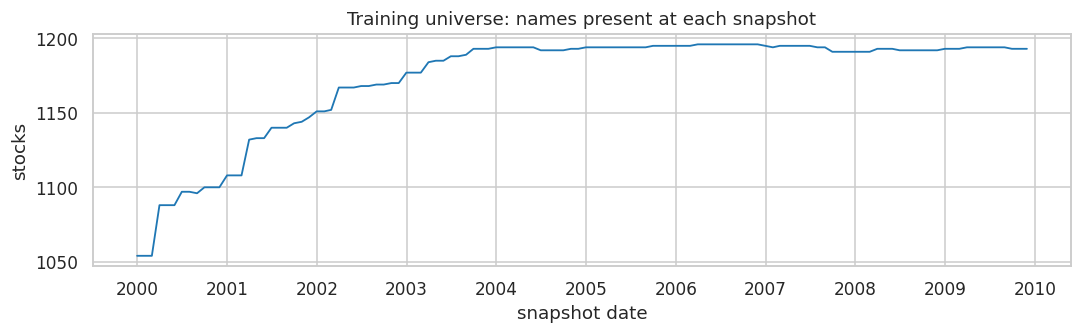

In [3]:
feature_summary = train[features].agg(["min", "max", "mean", "std", "nunique"]).T
feature_summary = feature_summary.sort_values("std")
display(feature_summary.round(4))

label = train[TARGET]
print(
    f"train R1M_Usd: mean {label.mean():.4f}, median {label.median():.4f}, "
    f"min {label.min():.3f}, max {label.max():.3f}"
)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(train_counts.index, train_counts.values, color="#1f77b4", lw=1.2)
ax.set_title("Training universe: names present at each snapshot")
ax.set_ylabel("stocks")
ax.set_xlabel("snapshot date")
fig.tight_layout()
plt.show()


## Working names

The selection math uses the column names as labels only. A wrong economic reading changes the last paragraph of this notebook, where the surviving columns are described in words. It does not change the score. Names marked "Low" are the ones to be careful with in that paragraph.


In [4]:
glossary = pd.DataFrame(GLOSSARY, columns=["feature", "working meaning", "name confidence"])
display(glossary)

first_date = train["date"].iloc[0]
sample_cols = ["stock_id", "Fcf_Yld", "Div_Yld", "Ev_Ebitda", "Debtequity", "Share_Turn_12M", "Capex_Sales", TARGET]
sample = train.loc[train["date"] == first_date, sample_cols].head(8)
print(f"Eight names on the {stamp(first_date)} snapshot. The factor entries are percentile bins, not raw ratios.")
display(sample)


,feature,working meaning,name confidence
0,Ocf_Toa,Operating cash flow / assets,Medium. Near Ocf_Ta in name; the correlation decides whether they are duplicates.
1,Ocf_Ta,"Operating cash flow / assets, second coding",Medium. Kept separate from Ocf_Toa unless |correlation| reaches 0.80.
2,Ocf_Ce,"Operating cash flow / common equity, or cash earnings",Low. The score does not depend on this reading.
3,Ocf_Tbv,Operating cash flow / tangible book,Medium.
4,Fcf_Tbv,Free cash flow / tangible book,Medium. Tightly tied to Ocf_Tbv in the training correlations.
5,Fcf_Yld,Free-cash-flow yield,High.
6,Div_Yld,Dividend yield,High.
7,Bb_Yld,Buyback yield,Medium.
8,Netdebtyield,A net-debt yield or a related valuation spread,Low.
9,Ev_Ebitda,Enterprise value / EBITDA,High.


Eight names on the 1999-12-31 snapshot. The factor entries are percentile bins, not raw ratios.


,stock_id,Fcf_Yld,Div_Yld,Ev_Ebitda,Debtequity,Share_Turn_12M,Capex_Sales,R1M_Usd
0,1,0.63,0.01,0.57,0.88,0.33,0.90,-0.042
1,2,0.28,0.40,0.97,0.10,0.92,0.84,0.461
2,3,0.87,0.66,0.17,0.95,0.38,0.06,-0.118
3,4,0.15,0.91,0.51,0.71,0.48,0.90,-0.051
4,5,0.45,0.49,0.93,0.02,0.93,0.41,-0.093
5,6,0.17,0.85,0.77,0.78,0.25,0.86,-0.171
6,7,0.03,1.00,0.25,0.44,0.04,0.97,-0.031
7,8,0.56,0.63,0.76,0.49,0.12,0.50,0.050


## Several columns are one idea, measured more than once

A linear model that is handed three share-turnover columns has to split one piece of information across three noisy coefficients. Lasso, which chapters 23 and 34 use for this reason, can set some of those coefficients to zero. Ridge shrinks them and keeps all three. The all-20 strategy in this notebook is the ridge version, so it lives with the duplicates. The subset keeps one representative when the absolute correlation is 0.80 or higher.

The picture is average-linkage clustering on the distance `1 - |correlation|`, fit on the training rows. Distance 0.20 means `|correlation| = 0.80`. Distance 0.30 means `|correlation| = 0.70`. The greedy rule later in the notebook uses that 0.80 gate on the same training correlation. There are more clusters than the ten seats we are allowed, so the gate is required and it is not enough. The score has to leave some weakly related columns out.

Principal components make the same point, which is the point of chapters 26a and 26b: when a block moves together, one direction soaks up the shared variation, and treating the columns as independent overstates how much information is there. The components are a picture. The submitted list stays in the original columns, because the assignment asks for a subset of the factor measurements.


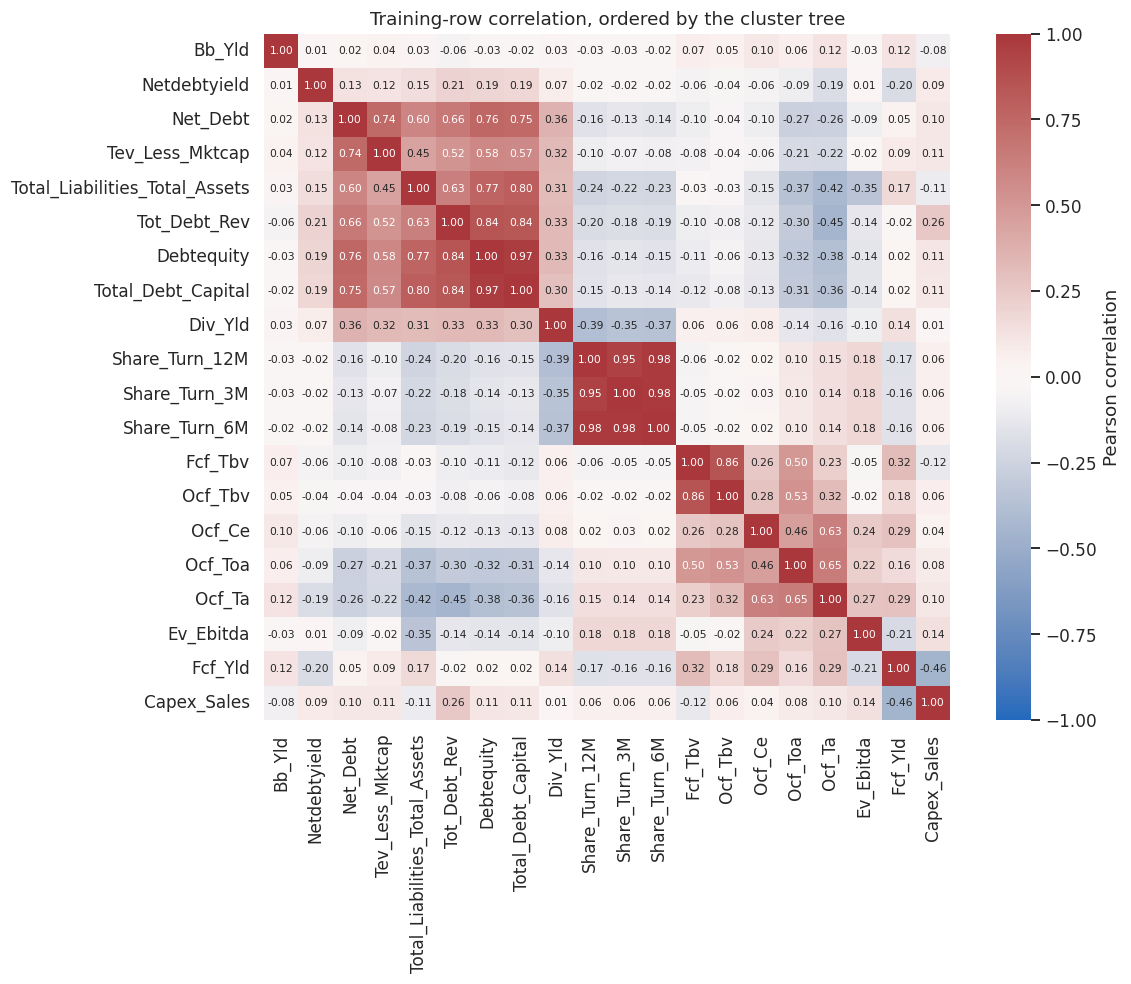

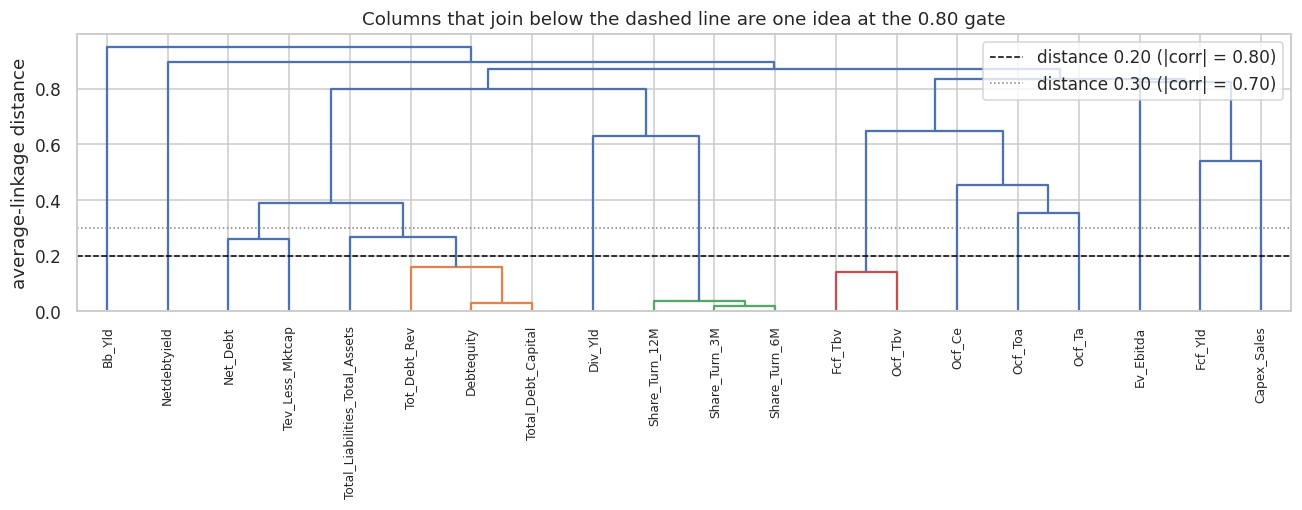

distance 0.20: 15 clusters, 3 with more than one column
    Debtequity, Tot_Debt_Rev, Total_Debt_Capital
    Share_Turn_12M, Share_Turn_3M, Share_Turn_6M
    Fcf_Tbv, Ocf_Tbv
   alone: Bb_Yld, Capex_Sales, Div_Yld, Ev_Ebitda, Fcf_Yld, Net_Debt, Netdebtyield, Ocf_Ce, Ocf_Ta, Ocf_Toa, Tev_Less_Mktcap, Total_Liabilities_Total_Assets
distance 0.30: 13 clusters, 4 with more than one column
    Debtequity, Tot_Debt_Rev, Total_Debt_Capital, Total_Liabilities_Total_Assets
    Net_Debt, Tev_Less_Mktcap
    Share_Turn_12M, Share_Turn_3M, Share_Turn_6M
    Fcf_Tbv, Ocf_Tbv
   alone: Bb_Yld, Capex_Sales, Div_Yld, Ev_Ebitda, Fcf_Yld, Netdebtyield, Ocf_Ce, Ocf_Ta, Ocf_Toa
multi-column clusters at 0.20 match the plan's scouting pass: True
PCA on standardized training features: 7 components to reach 80% of variance
PC1 Debtequity (+0.37), Total_Debt_Capital (+0.37), Tot_Debt_Rev (+0.35), Total_Liabilities_Total_Assets (+0.34), Net_Debt (+0.33)
PC2 Share_Turn_6M (+0.41), Share_Turn_12M (+0.41), Share_T

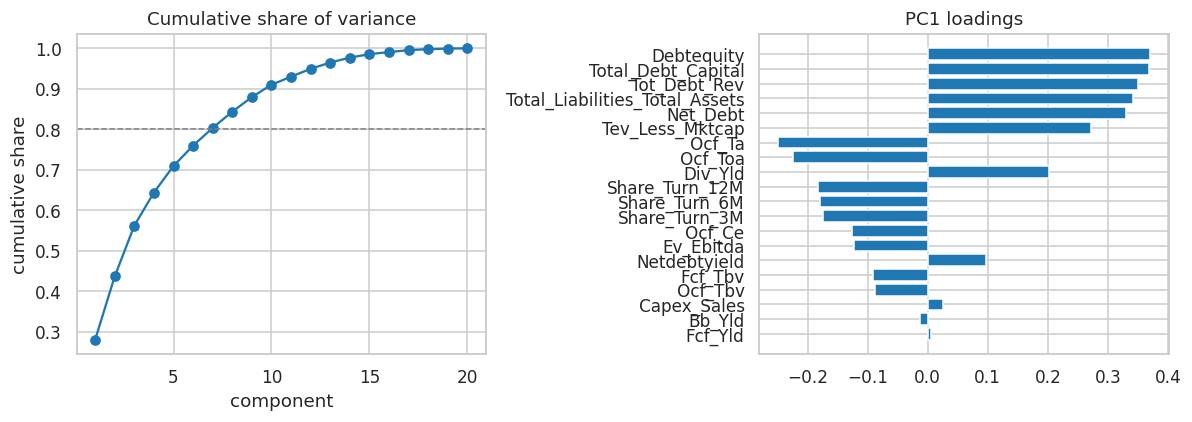

In [5]:
corr = train[features].corr()
distance = 1.0 - corr.abs()
sym = (distance.values + distance.values.T) / 2.0
np.fill_diagonal(sym, 0.0)
link = linkage(squareform(sym, checks=False), method="average")
leaf_order = [features[i] for i in leaves_list(link)]
corr_ordered = corr.loc[leaf_order, leaf_order]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_ordered,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True,
    ax=ax,
    cbar_kws={"label": "Pearson correlation"},
)
ax.set_title("Training-row correlation, ordered by the cluster tree")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.8))
dendrogram(link, labels=features, ax=ax, color_threshold=0.20, leaf_rotation=90, leaf_font_size=8)
ax.axhline(0.20, color="black", ls="--", lw=1, label="distance 0.20 (|corr| = 0.80)")
ax.axhline(0.30, color="gray", ls=":", lw=1, label="distance 0.30 (|corr| = 0.70)")
ax.set_ylabel("average-linkage distance")
ax.set_title("Columns that join below the dashed line are one idea at the 0.80 gate")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


def multi_clusters(threshold):
    labels = fcluster(link, t=threshold, criterion="distance")
    groups = {}
    for name, label in zip(features, labels):
        groups.setdefault(int(label), []).append(name)
    multi = [sorted(members) for members in groups.values() if len(members) > 1]
    singles = sorted(members[0] for members in groups.values() if len(members) == 1)
    return multi, singles


plan_clusters = [
    {"Tot_Debt_Rev", "Debtequity", "Total_Debt_Capital"},
    {"Share_Turn_3M", "Share_Turn_6M", "Share_Turn_12M"},
    {"Fcf_Tbv", "Ocf_Tbv"},
]
for threshold in (0.20, 0.30):
    multi, singles = multi_clusters(threshold)
    print(f"distance {threshold:.2f}: {len(multi) + len(singles)} clusters, {len(multi)} with more than one column")
    for members in multi:
        print("   ", ", ".join(members))
    print("   alone:", ", ".join(singles))

found = {frozenset(members) for members in multi_clusters(0.20)[0]}
expected = {frozenset(members) for members in plan_clusters}
print("multi-column clusters at 0.20 match the plan's scouting pass:" , found == expected)

scaled = StandardScaler().fit_transform(train[features].to_numpy(dtype=float))
pca = PCA(random_state=0).fit(scaled)
share = np.cumsum(pca.explained_variance_ratio_)
print(f"PCA on standardized training features: {int(np.searchsorted(share, 0.80) + 1)} components to reach 80% of variance")
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"])
for component in ("PC1", "PC2"):
    top = loadings[component].abs().sort_values(ascending=False).head(5)
    print(component, ", ".join(f"{name} ({loadings.loc[name, component]:+.2f})" for name in top.index))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(1, len(share) + 1), share, marker="o", color="#1f77b4")
axes[0].axhline(0.80, color="gray", ls="--", lw=1)
axes[0].set_title("Cumulative share of variance")
axes[0].set_xlabel("component")
axes[0].set_ylabel("cumulative share")
pc1 = loadings["PC1"].reindex(loadings["PC1"].abs().sort_values(ascending=True).index)
axes[1].barh(pc1.index, pc1.values, color="#1f77b4")
axes[1].set_title("PC1 loadings")
fig.tight_layout()
plt.show()


## Each column alone is a weak monthly rank signal

The trading rule only needs an ordering inside the month. The measure that matches that job is a Spearman correlation, computed inside each month between the column and raw `R1M_Usd`, then averaged across months. Spearman uses ranks, so one return of 20× cannot decide which column looks predictive.

The t-stat is `mean / (std / sqrt(n_months))`, with the sample standard deviation. An information coefficient near 0.01 is ordinary for a monthly equity factor. The whiskers on the chart are the standard error, `std / sqrt(n_months)`. A whisker that crosses zero is a column whose average rank correlation is small relative to its month-to-month variation.

The same training labels have a fat tail. A handful of rows with absolute return above 1 can own a large share of the sum of squared returns. A squared-error fit on the raw return spends its energy there. That is why the fit target in the next section is clipped inside the month and then demeaned, while every rank metric and every portfolio profit still uses the raw return.

These information coefficients are training months only.


,feature,mean_ic,std_ic,t_ic,hit_rate,n_months,stability,ic_stat
0,Ocf_Ce,0.0113,0.0694,1.7819,0.5917,120,0.1833,0.0021
1,Fcf_Yld,0.0104,0.0837,1.3653,0.5167,120,0.0333,0.0003
2,Ocf_Ta,0.0084,0.0907,1.0193,0.5083,120,0.0167,0.0001
3,Ocf_Toa,0.0080,0.0746,1.1736,0.5250,120,0.0500,0.0004
4,Ocf_Tbv,0.0065,0.0464,1.5453,0.5333,120,0.0667,0.0004
5,Tev_Less_Mktcap,0.0029,0.1149,0.2771,0.5083,120,0.0167,0.0000
6,Total_Debt_Capital,0.0026,0.1044,0.2686,0.5167,120,0.0333,0.0001
7,Fcf_Tbv,0.0025,0.0435,0.6252,0.5000,120,0.0000,0.0000
8,Debtequity,0.0020,0.1088,0.2019,0.4833,120,0.0333,0.0001
9,Div_Yld,-0.0002,0.1357,-0.0126,0.4750,120,0.0500,0.0000


training columns with |t| >= 2: 0
largest |mean IC| is 0.0113 (Ocf_Ce)
146 training rows have |R1M_Usd| > 1. They account for 50.0% of the sum of squared returns. The largest training return is 27.23.


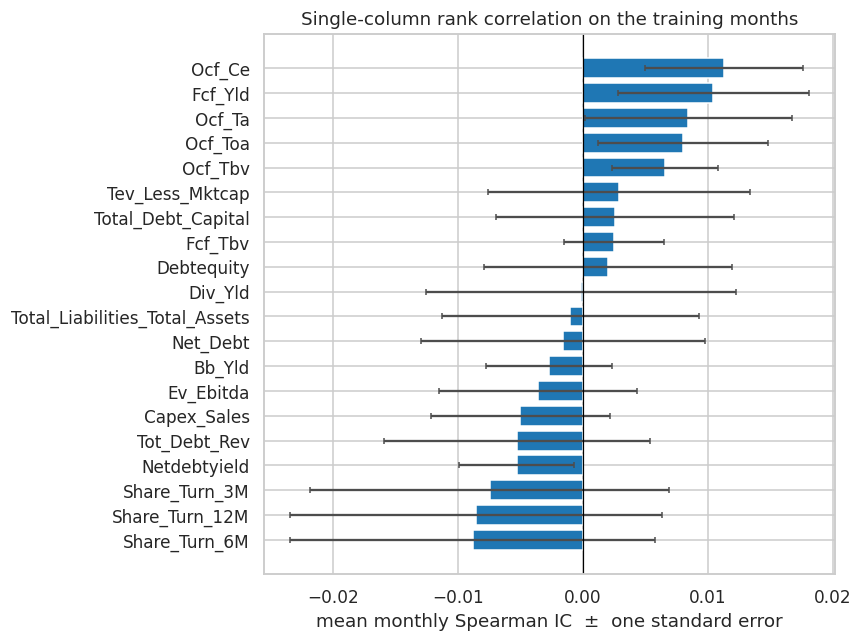

In [6]:
ic_table = feature_association(
    train[features].to_numpy(dtype=float),
    train[TARGET].to_numpy(dtype=float),
    train["date"].to_numpy(),
    features,
)
ic_view = ic_table.sort_values("mean_ic", ascending=False).reset_index(drop=True)
display(ic_view.round(4))
n_clear = int((ic_view["t_ic"].abs() >= 2).sum())
print(f"training columns with |t| >= 2: {n_clear}")
print(
    "largest |mean IC| is "
    f"{ic_view['mean_ic'].abs().max():.4f} "
    f"({ic_view.loc[ic_view['mean_ic'].abs().idxmax(), 'feature']})"
)

y_raw = train[TARGET].to_numpy(dtype=float)
extreme = np.abs(y_raw) > 1
tail_share = float(np.sum(y_raw[extreme] ** 2) / np.sum(y_raw ** 2))
print(
    f"{int(extreme.sum())} training rows have |R1M_Usd| > 1. "
    f"They account for {tail_share:.1%} of the sum of squared returns. "
    f"The largest training return is {y_raw.max():.2f}."
)

plot_ic = ic_view.sort_values("mean_ic")
se = plot_ic["std_ic"] / np.sqrt(plot_ic["n_months"])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_ic["feature"], plot_ic["mean_ic"], xerr=se, color="#1f77b4", ecolor="#4d4d4d", capsize=2)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("mean monthly Spearman IC  ±  one standard error")
ax.set_title("Single-column rank correlation on the training months")
fig.tight_layout()
plt.show()


## How a column earns a seat

`select_features` uses only the rows it is given. On the full training file that is six expanding folds. The first fit uses the 48 snapshots through November 2003. Each validation block is the next 12 snapshots. Later folds include the crisis years, so a column that worked only in the early sample loses frequency. The first walk-forward origin has 60 snapshots and therefore one fold. Frequency on that origin is coarse: a column is either in or out.

**Fit target.** Inside each month, clip `R1M_Usd` to that month's 1st and 99th percentiles, then subtract the median of the clipped values. With about 1,100 names, each tail is about a dozen stocks. The clip and the median are computed on the rows inside the fit. When the model is scored, the score uses raw `R1M_Usd`. Predictions are used only to rank inside the month, so the unit of the fit target does not change who is held.

**Lasso frequency.** For each fold, the last 12 months of that fold's training window are an inner block. They stay inside the outer training window. The validation months are untouched. On the grid `logspace(-5, -2, 16)`, a scaler is fit on the inner-fit rows only, then a lasso is fit to the fit target. The alpha's score is the mean monthly Spearman correlation between its prediction and raw return on the inner block. Alphas within 0.002 of the best score are eligible, and the largest of those alphas is kept. A flat path then prefers the sparser model, which is the situation chapter 34 ran into. That alpha is refit on the whole outer training window. A column is selected on the fold when the absolute coefficient exceeds `1e-8`. Frequency is the fraction of folds that select it.

The same inner loop is repeated with negative mean squared error on the fit target. That alpha's selection frequency is stored as `lasso_mse_frequency`. It does not enter the score. The 0.002 band is in the units of whichever score is being used. Spearman values here are near 0.01, so 0.002 is a real slice of the path. Squared error on a demeaned monthly return moves by much less than 0.002 across this grid, so the band can cover every alpha and the rule then returns the largest alpha. That is the side column doing what the written rule says. It is not a vote.

**Permutation drop.** The same folds train a shallow random forest on the raw percentiles and the fit target: 200 trees, depth 3, at least 400 rows per leaf, `max_features="sqrt"`. Depth and leaf size are fixed because a rank correlation near 0.01 is easy for a deep forest to memorize. The baseline is the mean monthly Spearman of the forest's prediction on the validation months. Each column is then shuffled inside each validation month, five times, and the drop in that mean Spearman is recorded. A positive drop means the column's within-month ordering was helping the rank correlation. This is the strategy's question. Impurity importance, which chapter 29 reads off a tree, answers a different question: which column the tree happened to split on.

**What does not vote.** A small gradient-boosting model (100 trees, depth 2) records average gain on the same folds. It is a column on the scorecard so a disagreement is visible. It is not one of the four required model families, and it does not enter the score.

On the whole frame, each column also gets a mean monthly Spearman IC, a t-stat, and a hit rate. Stability is `2 * |hit rate - 0.5|`: 0 when the sign is a coin flip, 1 when every month has the same sign. `ic_stat` is `|mean IC| * stability`. The absolute average alone would promote a column whose sign flips every year. Stability is what punishes the flip.

**Score.** Min-max scale the permutation drop across the 20 columns, and min-max scale `ic_stat`. If the max equals the min, the scaled value is 0.

```text
score = 0.40 * lasso_frequency + 0.40 * perm_drop_scaled + 0.20 * ic_stat_scaled
```

A column is eligible when its lasso frequency is at least 0.5, or its permutation drop is positive, or `|t_ic|` is at least 1. Eligible columns are sorted by score, then by name. The greedy pass keeps a column when its absolute correlation with every column already kept is strictly below 0.80, and it stops at 10 names. If fewer than 3 columns are eligible, the next-highest scores from the full list are appended, still respecting the gate, until the list has 3 names or no name remains, and `weak_signal_fallback` is set. A list of 3 to 10 is allowed. Empty seats are not filled with columns that failed every check.

The picture before the fit is one lasso path on all training months, using this same alpha grid and the same fit target. It shows how correlated columns hand a coefficient from one column to another as the penalty rises. The path does not choose the subset. `select_features` does.


lasso path convergence warnings: 0
alpha grid: 1e-05, 1.58e-05, 2.51e-05, 3.98e-05, 6.31e-05, 0.0001, 0.000158, 0.000251, 0.000398, 0.000631, 0.001, 0.00158, 0.00251, 0.00398, 0.00631, 0.01


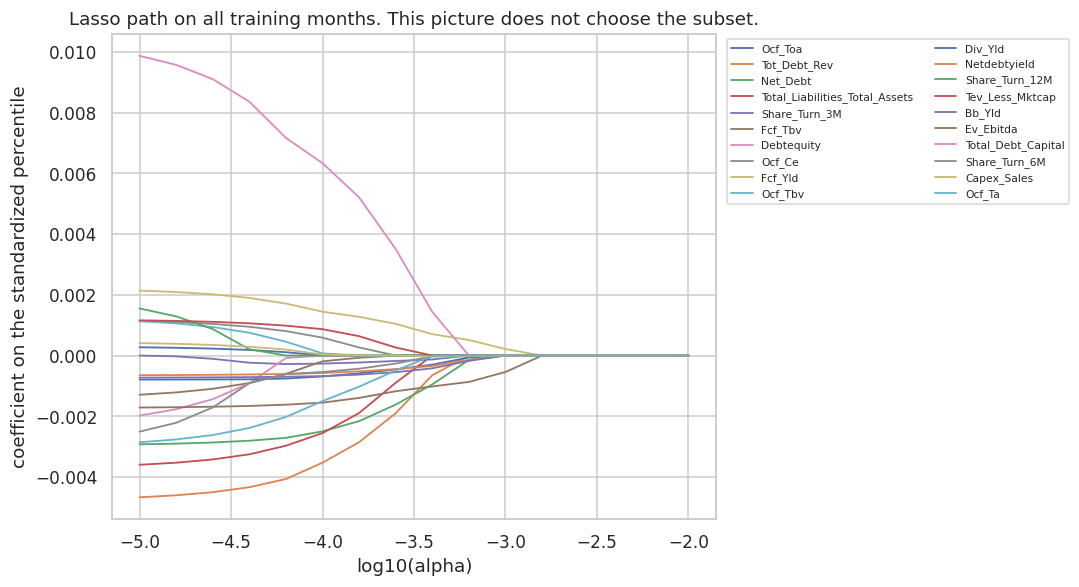

select_features on all 120 training snapshots
  fit fold train through 2003-11-30 | validate 2003-12-31 to 2004-11-30
  fit fold train through 2004-11-30 | validate 2004-12-31 to 2005-11-30
  fit fold train through 2005-11-30 | validate 2005-12-31 to 2006-11-30
  fit fold train through 2006-11-30 | validate 2006-12-31 to 2007-11-30
  fit fold train through 2007-11-30 | validate 2007-12-31 to 2008-11-30
  fit fold train through 2008-11-30 | validate 2008-12-31 to 2009-11-30
  6 fold(s), fallback=False, chose 10: Ev_Ebitda, Net_Debt, Div_Yld, Fcf_Yld, Tot_Debt_Rev, Ocf_Ce, Share_Turn_12M, Tev_Less_Mktcap, Fcf_Tbv, Total_Liabilities_Total_Assets
fold log


,train_last,val_first,val_last,n_train_months,lasso_alpha,best_inner_spearman,spearman_span,n_alphas_in_band,mse_alpha,best_neg_mse,neg_mse_span,n_mse_alphas_in_band,alphas_agree,forest_base_spearman,convergence_warnings,n_selected,n_selected_mse
0,2003-11-30,2003-12-31,2004-11-30,48,0.000040,0.018408,0.039501,4,0.01,-0.009051,0.000055,16,False,0.046104,0,18,0
1,2004-11-30,2004-12-31,2005-11-30,60,0.000158,0.018561,0.011305,7,0.01,-0.007085,0.000013,16,False,0.015682,0,15,0
2,2005-11-30,2005-12-31,2006-11-30,72,0.002512,0.003575,0.005949,4,0.01,-0.006367,0.000033,16,False,0.045068,0,1,0
3,2006-11-30,2006-12-31,2007-11-30,84,0.000063,0.031544,0.039725,5,0.01,-0.005997,0.000010,16,False,-0.068451,0,18,0
4,2007-11-30,2007-12-31,2008-11-30,96,0.000631,-0.048103,0.022561,1,0.01,-0.006150,0.000077,16,False,0.027103,0,7,0
5,2008-11-30,2008-12-31,2009-11-30,108,0.000251,0.030325,0.010825,3,0.01,-0.014633,0.000017,16,False,-0.021085,0,14,0


In [7]:
y_train_fit = y_fit_array(train[TARGET].to_numpy(dtype=float), train["date"].to_numpy())
x_train = train[features].to_numpy(dtype=float)
scaler_picture = StandardScaler().fit(x_train)
x_train_scaled = scaler_picture.transform(x_train)
path = []
path_warnings = 0
for alpha in ALPHAS:
    model, n_warn = fit_lasso(x_train_scaled, y_train_fit, alpha)
    path.append(model.coef_)
    path_warnings += n_warn
path = np.vstack(path)
print(f"lasso path convergence warnings: {path_warnings}")
print("alpha grid:", ", ".join(f"{a:.3g}" for a in ALPHAS))

fig, ax = plt.subplots(figsize=(10, 5.5))
for j, name in enumerate(features):
    ax.plot(np.log10(ALPHAS), path[:, j], lw=1.2, label=name)
ax.set_xlabel("log10(alpha)")
ax.set_ylabel("coefficient on the standardized percentile")
ax.set_title("Lasso path on all training months. This picture does not choose the subset.")
ax.legend(ncol=2, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

print("select_features on all 120 training snapshots")
final = select_features(train, features, verbose=True)
chosen = final["chosen"]
scorecard = final["scorecard"]
print("fold log")
display(final["fold_log"].round(6))


## Reading the scorecard

Frequency is a share of folds, so on six folds it moves in steps of one sixth. A permutation drop is a change in monthly Spearman correlation. A drop of 0.001 means that destroying the column's within-month order cost about 0.001 of rank correlation, which is the same order of magnitude as the single-column ICs. The gain column is the boosting diagnostic. Compare it with the permutation drop when you want to see whether a tree's favorite column actually helped the rank.

The decision text on each row is the greedy pass: kept, blocked by a correlation of at least 0.80 with a column already kept, or left out because 10 seats were already full. A row can be eligible and still lose its seat. That is the cap doing the job the correlation gate could not finish, because more than 10 columns clear at least one eligibility check.

`lasso_mse_frequency` is the side column. Read it next to the fold log. If every fold's mean-squared-error alpha is the largest alpha on the grid, the 0.002 band swallowed the whole mean-squared-error path, and a large alpha can zero every coefficient. That column stays out of the score.


,feature,score,lasso_frequency,lasso_mse_frequency,mean_coef,perm_drop,xgb_gain,mean_ic,t_ic,hit_rate,eligible,kept,decision
0,Ev_Ebitda,0.6749,1.0000,0.0,-0.0020,0.0010,0.0561,-0.0036,-0.4574,0.4667,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
1,Net_Debt,0.6744,0.6667,0.0,-0.0019,0.0028,0.0516,-0.0016,-0.1408,0.4750,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
2,Div_Yld,0.6660,0.8333,0.0,-0.0011,0.0020,0.0593,-0.0002,-0.0126,0.4750,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
3,Fcf_Yld,0.6100,0.8333,0.0,0.0013,0.0009,0.0637,0.0104,1.3653,0.5167,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0, |t_ic|>=1; passed the 0.80 correlation gate"
4,Tot_Debt_Rev,0.5726,0.6667,0.0,-0.0020,0.0010,0.0662,-0.0053,-0.4984,0.4417,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
5,Ocf_Ce,0.5723,0.5000,0.0,0.0007,0.0001,0.0538,0.0113,1.7819,0.5917,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0, |t_ic|>=1; passed the 0.80 correlation gate"
6,Share_Turn_12M,0.5221,0.8333,0.0,-0.0015,0.0001,0.0644,-0.0085,-0.5740,0.5083,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
7,Tev_Less_Mktcap,0.5116,0.5000,0.0,0.0009,0.0017,0.0818,0.0029,0.2771,0.5083,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
8,Fcf_Tbv,0.4502,0.6667,0.0,-0.0005,0.0002,0.0254,0.0025,0.6252,0.5000,True,True,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
9,Total_Liabilities_Total_Assets,0.4350,0.6667,0.0,-0.0026,-0.0000,0.0390,-0.0010,-0.0971,0.4833,True,True,kept; eligible on lasso_frequency>=0.5; passed the 0.80 correlation gate


weak_signal_fallback = False
subset_final (10): Ev_Ebitda, Net_Debt, Div_Yld, Fcf_Yld, Tot_Debt_Rev, Ocf_Ce, Share_Turn_12M, Tev_Less_Mktcap, Fcf_Tbv, Total_Liabilities_Total_Assets
eligible columns: 17. The list stops at 10.
MSE-chosen alpha equals the top of the grid on 6 of 6 folds. Those refits select 0 coefficients in total.
lasso convergence warnings inside the folds: 0


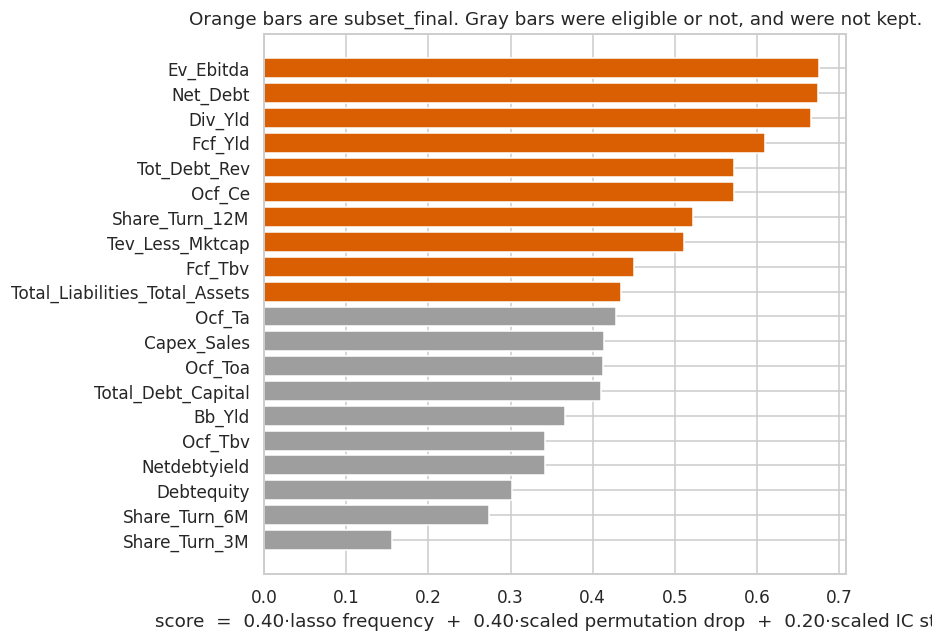

In [8]:
show_cols = [
    "feature", "score", "lasso_frequency", "lasso_mse_frequency", "mean_coef",
    "perm_drop", "xgb_gain", "mean_ic", "t_ic", "hit_rate", "eligible", "kept", "decision",
]
display(scorecard[show_cols].round(4))
print(f"weak_signal_fallback = {final['fallback']}")
print(f"subset_final ({len(chosen)}): {', '.join(chosen)}")
n_eligible = int(scorecard["eligible"].sum())
print(f"eligible columns: {n_eligible}. The list stops at {len(chosen)}.")
mse_note = final["fold_log"]
print(
    "MSE-chosen alpha equals the top of the grid on "
    f"{int((mse_note['mse_alpha'] - ALPHAS.max()).abs().lt(1e-15).sum())} of {len(mse_note)} folds. "
    f"Those refits select {int(mse_note['n_selected_mse'].sum())} coefficients in total."
)
print(f"lasso convergence warnings inside the folds: {int(mse_note['convergence_warnings'].sum())}")

fig, ax = plt.subplots(figsize=(8, 6))
plot_scores = scorecard.sort_values("score")
colors = ["#d95f02" if kept else "#9e9e9e" for kept in plot_scores["kept"]]
ax.barh(plot_scores["feature"], plot_scores["score"], color=colors)
ax.set_xlabel("score  =  0.40·lasso frequency  +  0.40·scaled permutation drop  +  0.20·scaled IC stat")
ax.set_title("Orange bars are subset_final. Gray bars were eligible or not, and were not kept.")
fig.tight_layout()
plt.show()


## Does the act of restricting help, on years the list has not seen?

`subset_final` is fit on every training month, including 2008 and 2009. That is the right list to deploy into 2010, because those years are part of the training sample the prompt gives us. It is the wrong object for the sentence "the restriction helped," because the list has already seen the years one might use as a practice test.

The process check rebuilds the list at five origins. At each origin, `select_features` sees only the snapshots strictly before that origin. The resulting list trades the next 12 snapshots. Ridge is refit before every traded snapshot on all earlier training rows. The feature list stays fixed for those 12 months. The all-20 ridge is refit on the same schedule. The equal-weight universe is the cross-sectional mean of raw `R1M_Usd`.

| Origin index | Last snapshot the selector may see | Snapshots then traded | Returns earned |
| --- | --- | --- | --- |
| 60 | 2004-11-30 | 2004-12 through 2005-11 | Jan 2005–Dec 2005 |
| 72 | 2005-11-30 | 2005-12 through 2006-11 | Jan 2006–Dec 2006 |
| 84 | 2006-11-30 | 2006-12 through 2007-11 | Jan 2007–Dec 2007 |
| 96 | 2007-11-30 | 2007-12 through 2008-11 | Jan 2008–Dec 2008 |
| 108 | 2008-11-30 | 2008-12 through 2009-11 | Jan 2009–Dec 2009 |

The path is 60 months long. The test file is not read in this section. The first origin has a single lasso fold, so its frequency is a coarse 0 or 1.

The plot's horizontal axis is the month the return was earned, which is the month after the snapshot. The equity curve is the cumulative product of gross monthly returns, the same construction as chapter 16.


origin 60: selector sees 1999-12-31 through 2004-11-30 (60 snapshots)
  reuse fold validate 2003-12-31 to 2004-11-30
  1 fold(s), fallback=False, chose 10: Fcf_Yld, Tev_Less_Mktcap, Ev_Ebitda, Netdebtyield, Ocf_Ce, Share_Turn_12M, Net_Debt, Div_Yld, Debtequity, Bb_Yld
origin 72: selector sees 1999-12-31 through 2005-11-30 (72 snapshots)
  reuse fold validate 2003-12-31 to 2004-11-30
  reuse fold validate 2004-12-31 to 2005-11-30
  2 fold(s), fallback=False, chose 10: Fcf_Yld, Ev_Ebitda, Div_Yld, Netdebtyield, Ocf_Ce, Tev_Less_Mktcap, Net_Debt, Share_Turn_12M, Capex_Sales, Tot_Debt_Rev
origin 84: selector sees 1999-12-31 through 2006-11-30 (84 snapshots)
  reuse fold validate 2003-12-31 to 2004-11-30
  reuse fold validate 2004-12-31 to 2005-11-30
  reuse fold validate 2005-12-31 to 2006-11-30
  3 fold(s), fallback=False, chose 10: Fcf_Yld, Ev_Ebitda, Tev_Less_Mktcap, Netdebtyield, Div_Yld, Ocf_Ce, Share_Turn_12M, Net_Debt, Tot_Debt_Rev, Total_Liabilities_Total_Assets
origin 96: selector

,origin_index,last_seen,n_folds,n_features,fallback,recall_vs_subset_final,subset,also_in_subset_final
0,60,2004-11-30,1,10,False,0.7,"Fcf_Yld, Tev_Less_Mktcap, Ev_Ebitda, Netdebtyield, Ocf_Ce, Share_Turn_12M, Net_Debt, Div_Yld, Debtequity, Bb_Yld","Fcf_Yld, Tev_Less_Mktcap, Ev_Ebitda, Ocf_Ce, Share_Turn_12M, Net_Debt, Div_Yld"
1,72,2005-11-30,2,10,False,0.8,"Fcf_Yld, Ev_Ebitda, Div_Yld, Netdebtyield, Ocf_Ce, Tev_Less_Mktcap, Net_Debt, Share_Turn_12M, Capex_Sales, Tot_Debt_Rev","Fcf_Yld, Ev_Ebitda, Div_Yld, Ocf_Ce, Tev_Less_Mktcap, Net_Debt, Share_Turn_12M, Tot_Debt_Rev"
2,84,2006-11-30,3,10,False,0.9,"Fcf_Yld, Ev_Ebitda, Tev_Less_Mktcap, Netdebtyield, Div_Yld, Ocf_Ce, Share_Turn_12M, Net_Debt, Tot_Debt_Rev, Total_Liabilities_Total_Assets","Fcf_Yld, Ev_Ebitda, Tev_Less_Mktcap, Div_Yld, Ocf_Ce, Share_Turn_12M, Net_Debt, Tot_Debt_Rev, Total_Liabilities_Total_Assets"
3,96,2007-11-30,4,10,False,0.8,"Div_Yld, Ev_Ebitda, Ocf_Ce, Fcf_Yld, Net_Debt, Tot_Debt_Rev, Ocf_Toa, Share_Turn_12M, Netdebtyield, Total_Liabilities_Total_Assets","Div_Yld, Ev_Ebitda, Ocf_Ce, Fcf_Yld, Net_Debt, Tot_Debt_Rev, Share_Turn_12M, Total_Liabilities_Total_Assets"
4,108,2008-11-30,5,10,False,0.8,"Ev_Ebitda, Net_Debt, Share_Turn_12M, Fcf_Yld, Ocf_Ce, Div_Yld, Tev_Less_Mktcap, Tot_Debt_Rev, Capex_Sales, Ocf_Toa","Ev_Ebitda, Net_Debt, Share_Turn_12M, Fcf_Yld, Ocf_Ce, Div_Yld, Tev_Less_Mktcap, Tot_Debt_Rev"


median recall of yearly lists against subset_final: 0.80
walk-forward paired mean (subset − all20) -0.00377, textbook t -1.86, Newey-West t -1.51, S 0.000375019
  ridge_all20: ann return 9.31%, ann vol 23.98%, Sharpe 0.491, max drawdown -49.03%
  ridge_subset: ann return 5.06%, ann vol 21.32%, Sharpe 0.340, max drawdown -45.41%
  equal_weight: ann return 7.62%, ann vol 23.19%, Sharpe 0.433, max drawdown -49.51%


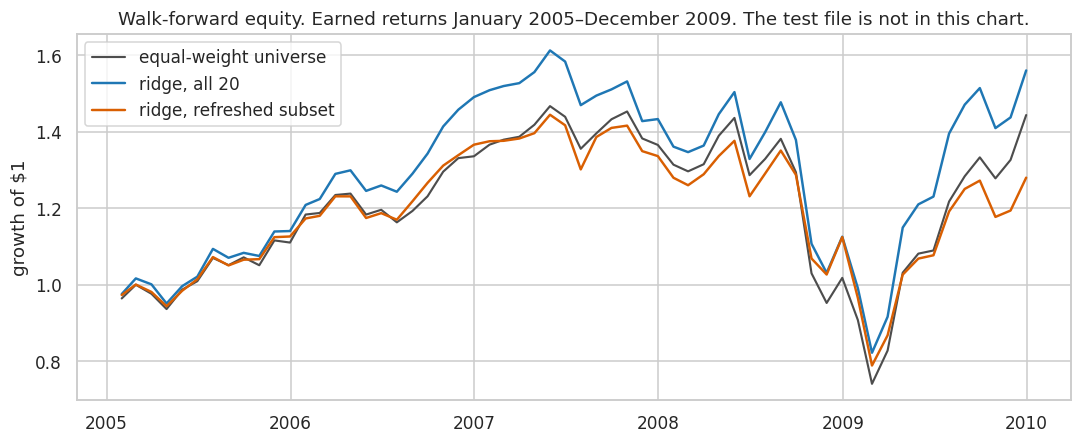

In [9]:
order, bounds = month_bounds(train["date"].to_numpy())
assert list(range(60, 120)) == [i for origin in ORIGIN_LAST_SEEN for i in range(origin, origin + 12)]

origin_results = {}
for origin, expected_last in ORIGIN_LAST_SEEN.items():
    assert order[origin - 1] == expected_last, (origin, order[origin - 1], expected_last)
    start_row = bounds[order[origin]][0]
    past = train.iloc[:start_row]
    print(
        f"origin {origin}: selector sees {stamp(past['date'].iloc[0])} through {stamp(past['date'].iloc[-1])} "
        f"({past['date'].nunique()} snapshots)"
    )
    origin_results[origin] = select_features(past, features, verbose=True)

print("ridge walk-forward, all 20 columns, snapshots 2004-12 through 2009-11")
ridge_all_wf = expanding_ridge_predictions(train, features, range(60, 120))
books_all_wf, weights_all_wf, ics_all_wf = quintile_books(
    ridge_all_wf["pred"], ridge_all_wf["y"], ridge_all_wf["dates"], ridge_all_wf["stock_ids"]
)
ew_wf, weights_ew_wf, _ = equal_weight_books(
    ridge_all_wf["y"], ridge_all_wf["dates"], ridge_all_wf["stock_ids"]
)

subset_books = []
for origin, result in origin_results.items():
    part = expanding_ridge_predictions(train, result["chosen"], range(origin, origin + 12))
    books, weights, ics = quintile_books(part["pred"], part["y"], part["dates"], part["stock_ids"])
    books["origin_index"] = origin
    books["origin_last_seen"] = order[origin - 1]
    books["subset"] = "|".join(result["chosen"])
    books["fallback"] = result["fallback"]
    subset_books.append(books)
books_sub_wf = pd.concat(subset_books, ignore_index=True)
assert list(books_sub_wf["date"]) == list(books_all_wf["date"]) == list(ew_wf["date"])

yearly = pd.DataFrame(
    {
        "date": books_sub_wf["date"],
        "origin_index": books_sub_wf["origin_index"],
        "origin_last_seen": books_sub_wf["origin_last_seen"],
        "subset": books_sub_wf["subset"],
        "ridge_all20": books_all_wf["ret_raw"].to_numpy(),
        "ridge_subset": books_sub_wf["ret_raw"].to_numpy(),
        "equal_weight": ew_wf["ret_raw"].to_numpy(),
    }
)
assert len(yearly) == 60

recalls = []
overlap_rows = []
final_set = set(chosen)
for origin, result in origin_results.items():
    names = result["chosen"]
    rec = list_recall(names, chosen)
    recalls.append(rec)
    overlap_rows.append(
        {
            "origin_index": origin,
            "last_seen": order[origin - 1],
            "n_folds": result["n_folds"],
            "n_features": len(names),
            "fallback": result["fallback"],
            "recall_vs_subset_final": rec,
            "subset": ", ".join(names),
            "also_in_subset_final": ", ".join(n for n in names if n in final_set),
        }
    )
overlap_table = pd.DataFrame(overlap_rows)
median_recall = float(np.median(recalls))
display(overlap_table)
print(f"median recall of yearly lists against subset_final: {median_recall:.2f}")

wf_perf = {
    "ridge_all20": performance_from_returns(yearly["ridge_all20"]),
    "ridge_subset": performance_from_returns(yearly["ridge_subset"]),
    "equal_weight": performance_from_returns(yearly["equal_weight"]),
}
wf_paired_mean, wf_paired_t = paired_t(yearly["ridge_subset"] - yearly["ridge_all20"])
wf_nw_t, wf_nw_s = newey_west_t(yearly["ridge_subset"] - yearly["ridge_all20"])
print(
    f"walk-forward paired mean (subset − all20) {wf_paired_mean:.5f}, "
    f"textbook t {wf_paired_t:.2f}, Newey-West t {wf_nw_t:.2f}, S {wf_nw_s:.6g}"
)
for name, stats in wf_perf.items():
    print(
        f"  {name}: ann return {stats['ann_return']:.2%}, "
        f"ann vol {stats['ann_vol']:.2%}, Sharpe {stats['sharpe']:.3f}, "
        f"max drawdown {stats['max_drawdown']:.2%}"
    )

fig, ax = plt.subplots(figsize=(10, 4.2))
x_wf = earned_month(yearly["date"])
ax.plot(x_wf, wf_perf["equal_weight"]["equity"], color="#4d4d4d", lw=1.4, label="equal-weight universe")
ax.plot(x_wf, wf_perf["ridge_all20"]["equity"], color="#1f77b4", lw=1.6, label="ridge, all 20")
ax.plot(x_wf, wf_perf["ridge_subset"]["equity"], color="#d95f02", lw=1.6, label="ridge, refreshed subset")
ax.set_title("Walk-forward equity. Earned returns January 2005–December 2009. The test file is not in this chart.")
ax.set_ylabel("growth of $1")
ax.legend()
fig.tight_layout()
plt.show()


## Freeze the list

The file below is the list the test backtest is allowed to use. It is `select_features` on all 120 training snapshots. The yearly lists above are evidence about the selection process. They are not a second submitted subset. After this cell, the test file may be loaded for the backtest.


In [10]:
kept_rows = scorecard.loc[scorecard["kept"]].sort_values("greedy_order")
subset_out = kept_rows.rename(columns={"decision": "reason", "t_ic": "t_stat"})[
    ["feature", "score", "lasso_frequency", "perm_drop", "mean_ic", "t_stat", "reason"]
]
assert list(subset_out["feature"]) == chosen
subset_path = HERE / "subset_final.csv"
score_path = HERE / "feature_scorecard.csv"
yearly_path = HERE / "yearly_walkforward.csv"
subset_out.to_csv(subset_path, index=False)
scorecard.to_csv(score_path, index=False)
yearly.to_csv(yearly_path, index=False)
FROZEN = True
print(f"wrote {subset_path.name} ({len(subset_out)} rows), {score_path.name}, {yearly_path.name}")
print("The test file has not been used in a model, a strategy metric, or a plot.")
display(subset_out.round(4))


wrote subset_final.csv (10 rows), feature_scorecard.csv, yearly_walkforward.csv
The test file has not been used in a model, a strategy metric, or a plot.


,feature,score,lasso_frequency,perm_drop,mean_ic,t_stat,reason
0,Ev_Ebitda,0.6749,1.0000,0.0010,-0.0036,-0.4574,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
1,Net_Debt,0.6744,0.6667,0.0028,-0.0016,-0.1408,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
2,Div_Yld,0.6660,0.8333,0.0020,-0.0002,-0.0126,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
3,Fcf_Yld,0.6100,0.8333,0.0009,0.0104,1.3653,"kept; eligible on lasso_frequency>=0.5, perm_drop>0, |t_ic|>=1; passed the 0.80 correlation gate"
4,Tot_Debt_Rev,0.5726,0.6667,0.0010,-0.0053,-0.4984,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
5,Ocf_Ce,0.5723,0.5000,0.0001,0.0113,1.7819,"kept; eligible on lasso_frequency>=0.5, perm_drop>0, |t_ic|>=1; passed the 0.80 correlation gate"
6,Share_Turn_12M,0.5221,0.8333,0.0001,-0.0085,-0.5740,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
7,Tev_Less_Mktcap,0.5116,0.5000,0.0017,0.0029,0.2771,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
8,Fcf_Tbv,0.4502,0.6667,0.0002,0.0025,0.6252,"kept; eligible on lasso_frequency>=0.5, perm_drop>0; passed the 0.80 correlation gate"
9,Total_Liabilities_Total_Assets,0.4350,0.6667,-0.0000,-0.0010,-0.0971,kept; eligible on lasso_frequency>=0.5; passed the 0.80 correlation gate


## One test pass

The deployed list is now frozen. Both column sets use the same ridge, `StandardScaler` then `Ridge(alpha=1.0)`, which is the first ridge example in chapter 23. Alpha is 1 for the 20-column model and for the subset. Tuning it belongs to a later part of the assignment. The scaler is fit on the training rows only. The fit target is the within-month clipped, demeaned return, built from the training rows only. The model is fit once on all 120 training snapshots and then predicts every test row. Refitting each test month on the same training file would reproduce the same coefficients.

The second model is the same shallow forest used in the permutation step, fit once on all training rows, once for each column set. It is there so a gap that exists only because ridge dislikes collinear columns can be seen as such. It is not refit along the yearly walk-forward.

**Book.** Each month, hold every stock whose prediction is at least the 80th percentile of predictions that month. Ties at the cutoff stay in. Equal-weight the names that are held. The month's return is the equal-weight mean of their raw `R1M_Usd`. A shallow forest can give many stocks the same prediction. The tie rule then keeps a wider book. That width is reported. It is the precommitted rule, not a second strategy.

**Reference line.** The equal-weight universe is the mean raw return of every name present that month.

**Measurements,** with `k = 12` because the series is monthly. Chapter 15b uses 252 on daily returns. The Sharpe subtracts no Treasury bill. It is comparable across books because every book is scaled the same way.

```text
annualized return = ((1 + r).prod()) ** (12 / len(r)) - 1
annualized vol    = r.std(ddof=1) * sqrt(12)
Sharpe            = (r.mean() / r.std(ddof=1)) * sqrt(12)
equity            = (1 + r).cumprod()
drawdown          = equity / equity.cummax() - 1
```

One-way turnover from month `t-1` to month `t` is `0.5 * sum(|w_t - w_{t-1}|)` over the union of names. Weights are `1/n_held` on held names and 0 on the others.

The paired difference is `d = r_subset - r_all20` on the same months. The textbook t-stat treats months as independent. The Newey-West t-stat uses lag 3 and Bartlett weights. Lag 3 covers a quarter of monthly dependence. If the long-run variance is not positive, the notebook reports the textbook t-stat and says so.

Two views of this same pass:

1. **Capped returns.** Clip each stock's raw return at 100% before the equal-weight average. The names held do not change. This asks whether one print of 20× decided the race. The primary numbers use unclipped returns. A flip in the Sharpe ranking under the cap is tail-driven, and the decision rule records that as no clear improvement.
2. **Cost haircut.** Subtract 10 bp times one-way turnover. Replacing the whole book costs 10 bp that month. This is a sensitivity, not a spread model. It is reported. It does not change the decision label.


test: 127,740 rows, 108 snapshots, 2009-12-31 to 2018-11-30, 1,195 stocks, 1109–1194 names per month
test R1M_Usd: mean 0.0114, median 0.0100, min -0.880, max 30.176
ridge_all20: average names held 237.0, min 222, max 239
ridge_subset: average names held 237.0, min 222, max 239
forest_all20: average names held 237.0, min 222, max 239
forest_subset: average names held 237.0, min 222, max 240
raw


,strategy,view,ann_return,ann_vol,sharpe,max_drawdown,mean_ic,months_ahead_of_ew,avg_one_way_turnover
0,equal_weight,raw,13.10%,15.63%,0.868,-20.64%,,,0.08%
3,ridge_all20,raw,16.28%,18.25%,0.921,-22.46%,0.0015,57.41%,13.06%
6,ridge_subset,raw,15.60%,17.34%,0.926,-20.89%,0.0062,58.33%,13.03%
9,forest_all20,raw,19.81%,20.85%,0.975,-25.45%,-0.0058,62.04%,14.00%
12,forest_subset,raw,17.71%,20.84%,0.890,-25.64%,-0.0043,54.63%,13.75%


capped


,strategy,view,ann_return,ann_vol,sharpe,max_drawdown,mean_ic,months_ahead_of_ew,avg_one_way_turnover
1,equal_weight,capped,11.36%,15.58%,0.771,-21.63%,,,0.08%
4,ridge_all20,capped,12.77%,18.33%,0.749,-23.17%,0.0015,54.63%,13.06%
7,ridge_subset,capped,13.80%,17.25%,0.838,-21.88%,0.0062,58.33%,13.03%
10,forest_all20,capped,13.32%,20.53%,0.713,-26.98%,-0.0058,58.33%,14.00%
13,forest_subset,capped,13.12%,20.15%,0.714,-26.42%,-0.0043,52.78%,13.75%


cost_haircut


,strategy,view,ann_return,ann_vol,sharpe,max_drawdown,mean_ic,months_ahead_of_ew,avg_one_way_turnover
2,equal_weight,cost_haircut,13.10%,15.63%,0.868,-20.64%,,,0.08%
5,ridge_all20,cost_haircut,16.10%,18.25%,0.912,-22.51%,0.0015,56.48%,13.06%
8,ridge_subset,cost_haircut,15.43%,17.33%,0.918,-20.94%,0.0062,56.48%,13.03%
11,forest_all20,cost_haircut,19.61%,20.85%,0.967,-25.49%,-0.0058,62.04%,14.00%
14,forest_subset,cost_haircut,17.52%,20.84%,0.882,-25.68%,-0.0043,54.63%,13.75%


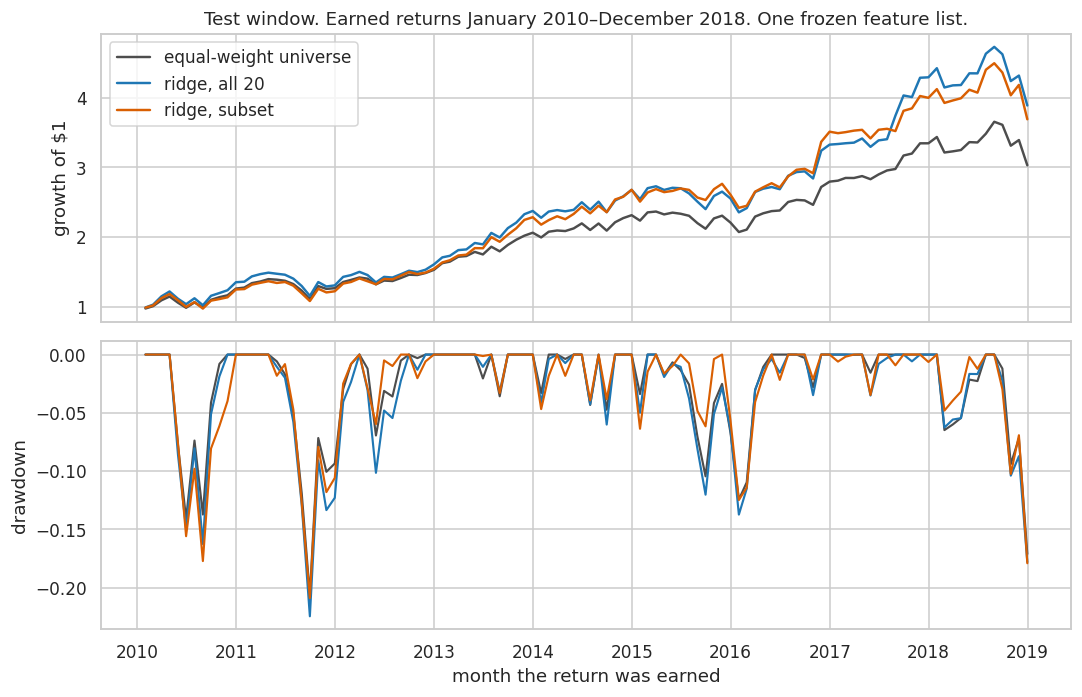

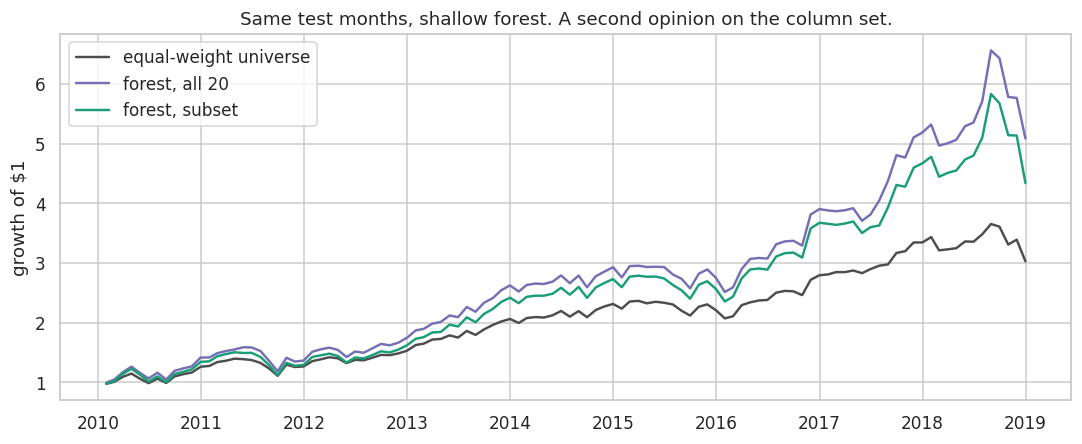

Ridge coefficients on the deployed subset, in standardized units, fit on the training rows.


,feature,ridge_coef,prefers
0,Ev_Ebitda,-0.0014,low percentile
1,Net_Debt,-0.0017,low percentile
2,Div_Yld,-0.0009,low percentile
3,Fcf_Yld,0.0012,high percentile
4,Tot_Debt_Rev,-0.0003,low percentile
5,Ocf_Ce,-0.0001,low percentile
6,Share_Turn_12M,-0.0006,low percentile
7,Tev_Less_Mktcap,0.0013,high percentile
8,Fcf_Tbv,-0.0005,low percentile
9,Total_Liabilities_Total_Assets,0.0003,high percentile


In [11]:
assert FROZEN is True
assert list(pd.read_csv(HERE / "subset_final.csv")["feature"]) == chosen

test = load_panel(TEST_PATH)
audit(test, "test")
print(
    f"test R1M_Usd: mean {test[TARGET].mean():.4f}, median {test[TARGET].median():.4f}, "
    f"min {test[TARGET].min():.3f}, max {test[TARGET].max():.3f}"
)

y_test = test[TARGET].to_numpy(dtype=float)
d_test = test["date"].to_numpy()
s_test = test["stock_id"].to_numpy()
ew_books, ew_weights, ew_ics = equal_weight_books(y_test, d_test, s_test)

pred_ridge_all, coef_all = fit_predict_once(train, test, features, "ridge")
pred_ridge_sub, coef_sub = fit_predict_once(train, test, chosen, "ridge")
pred_forest_all, _ = fit_predict_once(train, test, features, "forest")
pred_forest_sub, _ = fit_predict_once(train, test, chosen, "forest")

fitted = {
    "equal_weight": None,
    "ridge_all20": pred_ridge_all,
    "ridge_subset": pred_ridge_sub,
    "forest_all20": pred_forest_all,
    "forest_subset": pred_forest_sub,
}
books = {"equal_weight": ew_books}
weights = {"equal_weight": ew_weights}
ics = {"equal_weight": ew_ics}
for name, pred in fitted.items():
    if pred is None:
        continue
    b, w, ic = quintile_books(pred, y_test, d_test, s_test)
    assert list(b["date"]) == list(ew_books["date"])
    books[name] = b
    weights[name] = w
    ics[name] = ic
    print(f"{name}: average names held {b['n_held'].mean():.1f}, min {b['n_held'].min()}, max {b['n_held'].max()}")

comparison_rows = []
curves = {}
monthly = {}
for name in ("equal_weight", "ridge_all20", "ridge_subset", "forest_all20", "forest_subset"):
    rows, curve, turnover = strategy_views(
        books[name], weights[name], ew_books, ew_weights, ics[name], name
    )
    comparison_rows.extend(rows)
    curves[name] = curve
    monthly[name] = {
        "raw": books[name]["ret_raw"].to_numpy(),
        "capped": books[name]["ret_capped"].to_numpy(),
        "cost_haircut": books[name]["ret_raw"].to_numpy() - COST_PER_TURNOVER * turnover,
    }

comparison = pd.DataFrame(comparison_rows)
assert len(comparison) == 15
assert (comparison.groupby("strategy")["view"].nunique() == 3).all()


def show_metrics(frame):
    view = frame.copy()
    for col in ("ann_return", "ann_vol", "max_drawdown", "months_ahead_of_ew", "avg_one_way_turnover"):
        view[col] = frame[col].map(lambda x: "" if pd.isna(x) else f"{x:.2%}")
    view["sharpe"] = frame["sharpe"].map(lambda x: "" if pd.isna(x) else f"{x:.3f}")
    view["mean_ic"] = frame["mean_ic"].map(lambda x: "" if pd.isna(x) else f"{x:.4f}")
    return view


for view_name in ("raw", "capped", "cost_haircut"):
    print(view_name)
    display(show_metrics(comparison.loc[comparison["view"] == view_name]))

x_test = earned_month(ew_books["date"])
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for name, color, label in (
    ("equal_weight", "#4d4d4d", "equal-weight universe"),
    ("ridge_all20", "#1f77b4", "ridge, all 20"),
    ("ridge_subset", "#d95f02", "ridge, subset"),
):
    axes[0].plot(x_test, curves[name]["raw"]["equity"], color=color, lw=1.6, label=label)
    axes[1].plot(x_test, curves[name]["raw"]["drawdown"], color=color, lw=1.4)
axes[0].set_ylabel("growth of $1")
axes[0].set_title("Test window. Earned returns January 2010–December 2018. One frozen feature list.")
axes[0].legend()
axes[1].set_ylabel("drawdown")
axes[1].set_xlabel("month the return was earned")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
for name, color, label in (
    ("equal_weight", "#4d4d4d", "equal-weight universe"),
    ("forest_all20", "#7570b3", "forest, all 20"),
    ("forest_subset", "#1b9e77", "forest, subset"),
):
    ax.plot(x_test, curves[name]["raw"]["equity"], color=color, lw=1.6, label=label)
ax.set_title("Same test months, shallow forest. A second opinion on the column set.")
ax.set_ylabel("growth of $1")
ax.legend()
fig.tight_layout()
plt.show()

coef_table = pd.DataFrame({"feature": chosen, "ridge_coef": coef_sub})
coef_table["prefers"] = np.where(coef_table["ridge_coef"] >= 0, "high percentile", "low percentile")
print("Ridge coefficients on the deployed subset, in standardized units, fit on the training rows.")
display(coef_table.round(4))


## The decision

The label comes from the rule stated at the top of the notebook. The economic paragraph uses the ridge that actually trades the test window: a positive standardized coefficient means a higher percentile predicts a higher relative return, so the top quintile prefers the high end of that characteristic. A negative coefficient means the book prefers the low end. "High" is the vendor's rank of the raw characteristic. It is not a claim that the characteristic is attractive.

Duplicates named below are columns whose absolute training correlation with a kept column is at least 0.80. Near misses are eligible columns that lost a seat and are not that tightly tied to a kept column. Those near misses are the cost of the cap of 10.


In [12]:
raw_ix = comparison.loc[comparison["view"] == "raw"].set_index("strategy")
cap_ix = comparison.loc[comparison["view"] == "capped"].set_index("strategy")
cost_ix = comparison.loc[comparison["view"] == "cost_haircut"].set_index("strategy")

test_sharpe_gap = float(raw_ix.loc["ridge_subset", "sharpe"] - raw_ix.loc["ridge_all20", "sharpe"])
test_return_gap = float(raw_ix.loc["ridge_subset", "ann_return"] - raw_ix.loc["ridge_all20", "ann_return"])
test_paired_mean, test_paired_t = paired_t(monthly["ridge_subset"]["raw"] - monthly["ridge_all20"]["raw"])
test_nw_t, test_nw_s = newey_west_t(monthly["ridge_subset"]["raw"] - monthly["ridge_all20"]["raw"])
cap_sharpe_gap = float(cap_ix.loc["ridge_subset", "sharpe"] - cap_ix.loc["ridge_all20", "sharpe"])
cap_paired_mean, cap_paired_t = paired_t(monthly["ridge_subset"]["capped"] - monthly["ridge_all20"]["capped"])
cost_sharpe_gap = float(cost_ix.loc["ridge_subset", "sharpe"] - cost_ix.loc["ridge_all20", "sharpe"])
cost_paired_mean, cost_paired_t = paired_t(
    monthly["ridge_subset"]["cost_haircut"] - monthly["ridge_all20"]["cost_haircut"]
)
forest_sharpe_gap = float(raw_ix.loc["forest_subset", "sharpe"] - raw_ix.loc["forest_all20", "sharpe"])
forest_paired_mean, forest_paired_t = paired_t(monthly["forest_subset"]["raw"] - monthly["forest_all20"]["raw"])
wf_sharpe_gap = float(wf_perf["ridge_subset"]["sharpe"] - wf_perf["ridge_all20"]["sharpe"])

decision_label, decision_reasons = classify_result(
    test_sharpe_gap,
    test_return_gap,
    test_paired_mean,
    wf_sharpe_gap,
    wf_paired_mean,
    cap_sharpe_gap,
    median_recall,
)
if decision_label == "improvement":
    verb = "improves"
elif decision_label.startswith("simplification"):
    verb = "is a simplification with similar performance for"
else:
    verb = "does not clearly improve"
decision_sentence = (
    f"Restricting the model to {len(chosen)} features {verb} the long-only top-quintile strategy."
)

def report_pair(title, mean, t_stat, nw_t, nw_s):
    nw_text = f"Newey-West t {nw_t:.2f}" if np.isfinite(nw_t) else f"Newey-West variance was not positive (S={nw_s:.3g}); textbook t stands"
    print(f"{title}: mean {mean:.5f}, textbook t {t_stat:.2f}, {nw_text}")

report_pair("test ridge, subset − all20", test_paired_mean, test_paired_t, test_nw_t, test_nw_s)
print(f"capped-return paired mean {cap_paired_mean:.5f}, textbook t {cap_paired_t:.2f}, Sharpe gap {cap_sharpe_gap:.3f}")
print(f"cost-haircut paired mean {cost_paired_mean:.5f}, textbook t {cost_paired_t:.2f}, Sharpe gap {cost_sharpe_gap:.3f}")
print(
    "cost-haircut Sharpe ranking "
    + ("agrees with the raw ranking" if not signs_disagree(test_sharpe_gap, cost_sharpe_gap) else "flips relative to the raw ranking")
)
print(
    "forest Sharpe gap "
    f"{forest_sharpe_gap:.3f}; the forest "
    + ("agrees with the ridge on the sign of the gap" if not signs_disagree(test_sharpe_gap, forest_sharpe_gap) else "disagrees with the ridge on the sign of the gap")
)
print("decision:", decision_label)
for reason in decision_reasons:
    print(" -", reason)
print(decision_sentence)

abs_corr = final["corr"].abs()
dupe_lines = []
near_lines = []
kept_set = set(chosen)
for name in features:
    if name in kept_set:
        continue
    partner = abs_corr.loc[name, chosen].idxmax()
    value = float(abs_corr.loc[name, partner])
    if value >= CORR_GATE:
        dupe_lines.append(f"{name} (|corr| {value:.2f} with {partner})")
    elif bool(scorecard.set_index("feature").loc[name, "eligible"]):
        near_lines.append(name)

family_order = []
for name in chosen:
    family = FAMILIES[name]
    if family not in family_order:
        family_order.append(family)
sign_bits = [
    f"{row.feature} ({row.prefers}, ridge coef {row.ridge_coef:+.3f})"
    for row in coef_table.itertuples(index=False)
]
interpretation = (
    f"The deployed list has {len(chosen)} original columns: {', '.join(chosen)}. "
    f"Families represented: {', '.join(family_order)}. "
    f"On the ridge that trades the test window, the preferred side of each kept column is: {'; '.join(sign_bits)}. "
    f"Columns left out because |correlation| with a kept column is at least 0.80: "
    f"{'; '.join(dupe_lines) if dupe_lines else 'none'}. "
    f"Eligible columns that lost a seat and are not that tightly tied to a kept column: "
    f"{', '.join(near_lines) if near_lines else 'none'}. "
    + (
        "The weak-signal fallback filled the list toward 3 names."
        if final["fallback"]
        else "Eligibility alone supplied at least 3 names, so the weak-signal fallback stayed off."
    )
)
print(interpretation)
display(Markdown("**" + decision_sentence + "**\n\n" + interpretation))


test ridge, subset − all20: mean -0.00062, textbook t -0.42, Newey-West t -0.44
capped-return paired mean 0.00060, textbook t 0.65, Sharpe gap 0.089
cost-haircut paired mean -0.00062, textbook t -0.42, Sharpe gap 0.005
cost-haircut Sharpe ranking agrees with the raw ranking
forest Sharpe gap -0.085; the forest disagrees with the ridge on the sign of the gap
decision: no clear improvement
 - the test Sharpe gap and the walk-forward Sharpe gap disagree
Restricting the model to 10 features does not clearly improve the long-only top-quintile strategy.
The deployed list has 10 original columns: Ev_Ebitda, Net_Debt, Div_Yld, Fcf_Yld, Tot_Debt_Rev, Ocf_Ce, Share_Turn_12M, Tev_Less_Mktcap, Fcf_Tbv, Total_Liabilities_Total_Assets. Families represented: valuation multiple, leverage, dividend yield, cash-flow yield, cash flow, share turnover, enterprise value minus market cap, cash flow over tangible book. On the ridge that trades the test window, the preferred side of each kept column is: Ev_Ebi

**Restricting the model to 10 features does not clearly improve the long-only top-quintile strategy.**

The deployed list has 10 original columns: Ev_Ebitda, Net_Debt, Div_Yld, Fcf_Yld, Tot_Debt_Rev, Ocf_Ce, Share_Turn_12M, Tev_Less_Mktcap, Fcf_Tbv, Total_Liabilities_Total_Assets. Families represented: valuation multiple, leverage, dividend yield, cash-flow yield, cash flow, share turnover, enterprise value minus market cap, cash flow over tangible book. On the ridge that trades the test window, the preferred side of each kept column is: Ev_Ebitda (low percentile, ridge coef -0.001); Net_Debt (low percentile, ridge coef -0.002); Div_Yld (low percentile, ridge coef -0.001); Fcf_Yld (high percentile, ridge coef +0.001); Tot_Debt_Rev (low percentile, ridge coef -0.000); Ocf_Ce (low percentile, ridge coef -0.000); Share_Turn_12M (low percentile, ridge coef -0.001); Tev_Less_Mktcap (high percentile, ridge coef +0.001); Fcf_Tbv (low percentile, ridge coef -0.001); Total_Liabilities_Total_Assets (high percentile, ridge coef +0.000). Columns left out because |correlation| with a kept column is at least 0.80: Share_Turn_3M (|corr| 0.95 with Share_Turn_12M); Debtequity (|corr| 0.84 with Tot_Debt_Rev); Ocf_Tbv (|corr| 0.86 with Fcf_Tbv); Total_Debt_Capital (|corr| 0.84 with Tot_Debt_Rev); Share_Turn_6M (|corr| 0.98 with Share_Turn_12M). Eligible columns that lost a seat and are not that tightly tied to a kept column: Ocf_Toa, Netdebtyield, Bb_Yld, Capex_Sales, Ocf_Ta. Eligibility alone supplied at least 3 names, so the weak-signal fallback stayed off.

In [13]:
comparison_path = HERE / "strategy_comparison.csv"
comparison.to_csv(comparison_path, index=False)
yearly.to_csv(HERE / "yearly_walkforward.csv", index=False)

def fmt_pct(x):
    return "" if pd.isna(x) else f"{x:.2%}"

pretty = {
    "equal_weight": "Equal-weight universe",
    "ridge_all20": "Ridge, all 20",
    "ridge_subset": "Ridge, subset",
    "forest_all20": "Forest, all 20",
    "forest_subset": "Forest, subset",
}

def metric_line(frame, strategy):
    row = frame.loc[strategy]
    return (
        f"| {pretty[strategy]} | {fmt_pct(row.ann_return)} | {fmt_pct(row.ann_vol)} | "
        f"{row.sharpe:.3f} | {fmt_pct(row.max_drawdown)} | "
        f"{'' if pd.isna(row.mean_ic) else f'{row.mean_ic:.4f}'} | "
        f"{fmt_pct(row.months_ahead_of_ew)} | {fmt_pct(row.avg_one_way_turnover)} |"
    )

raw_table_lines = "\n".join(metric_line(raw_ix, name) for name in pretty)
yearly_lines = []
for row in overlap_table.itertuples(index=False):
    yearly_lines.append(
        f"- Origin {row.origin_index} (last seen {row.last_seen}, {row.n_folds} fold(s), "
        f"fallback {row.fallback}): {row.subset}. "
        f"Recall against subset_final: {row.recall_vs_subset_final:.2f}."
    )
nw_sentence = (
    f"Newey-West t = {test_nw_t:.2f} (lag 3, S = {test_nw_s:.6g})."
    if np.isfinite(test_nw_t)
    else f"The Newey-West variance was not positive (S = {test_nw_s:.6g}), so the textbook t-stat stands."
)
cluster_match = found == expected
learnings = f'''# Part 1 learnings from implementation

Status: **filled from the executed notebook** `02_part1_feature_selection.ipynb`. Numbers below are that run. This file does not re-decide the method in `01_plan.md`.

## 1. Subset the rule produced

`subset_final` has {len(chosen)} columns, in greedy order: {', '.join(chosen)}.

`weak_signal_fallback` is {final['fallback']}.

Scorecard path: `feature_scorecard.csv`. Chosen rows: `subset_final.csv`.

Yearly lists, each chosen only on snapshots before the origin:

{chr(10).join(yearly_lines)}

Median recall of those lists against `subset_final` is {median_recall:.2f}. The precommitted stability line is 0.50.

The first origin has one lasso fold, so its frequency is 0 or 1. That origin is included in the median.

## 2. Did the diagnostics match the plan's scouting measurements?

- Train shape {len(train):,} rows and {train['date'].nunique()} snapshots, test shape {len(test):,} rows and {test['date'].nunique()} snapshots, dates as in the plan, no missing values, no duplicate keys, earned-return months disjoint.
- Multi-column clusters at distance 0.20 {'match' if cluster_match else 'do not match'} the plan's scouting clusters (the leverage trio, the three turnover windows, and the two tangible-book cash-flow columns).
- Largest training |mean Spearman IC| is {ic_view['mean_ic'].abs().max():.4f}. Columns with |t| >= 2: {n_clear}. The plan's scouting pass found none.
- {int(extreme.sum())} training rows with |return| > 1 account for {tail_share:.1%} of the sum of squared training returns. Training max return {y_raw.max():.2f}. Test max return {test[TARGET].max():.2f}.
- Lasso convergence warnings inside the selection folds: {int(final['fold_log']['convergence_warnings'].sum())}. Path-picture warnings: {path_warnings}.
- Mean-squared-error alpha equals the top of the grid on {int((final['fold_log']['mse_alpha'] - ALPHAS.max()).abs().lt(1e-15).sum())} of {len(final['fold_log'])} full-sample folds, and those refits keep {int(final['fold_log']['n_selected_mse'].sum())} nonzero coefficients. The 0.002 band is wide relative to the mean-squared-error gaps, so the side column records the sparsest alpha and, on this grid, an empty set. It does not vote.

## 3. Walk-forward inside the training years

Source file: `yearly_walkforward.csv`. Earned returns January 2005 through December 2009 (60 months).

- Ridge, all 20 features: annualized return {wf_perf['ridge_all20']['ann_return']:.2%}, volatility {wf_perf['ridge_all20']['ann_vol']:.2%}, Sharpe {wf_perf['ridge_all20']['sharpe']:.3f}, max drawdown {wf_perf['ridge_all20']['max_drawdown']:.2%}.
- Ridge, refreshed subset: annualized return {wf_perf['ridge_subset']['ann_return']:.2%}, volatility {wf_perf['ridge_subset']['ann_vol']:.2%}, Sharpe {wf_perf['ridge_subset']['sharpe']:.3f}, max drawdown {wf_perf['ridge_subset']['max_drawdown']:.2%}.
- Equal-weight universe: annualized return {wf_perf['equal_weight']['ann_return']:.2%}, Sharpe {wf_perf['equal_weight']['sharpe']:.3f}.
- Monthly difference, subset minus all-20: mean {wf_paired_mean:.5f}, textbook t {wf_paired_t:.2f}, Newey-West t {wf_nw_t:.2f}.
- Sharpe gap (subset minus all-20): {wf_sharpe_gap:.3f}.

This path is the evidence that the restriction was chosen before the year it traded. It is not the official test.

## 4. Test backtest, one pass

Return window: January 2010 through December 2018 (snapshots 2009-12-31 through 2018-11-30).

Source file: `strategy_comparison.csv`. The table is the raw view.

| Strategy | Ann. return | Ann. vol | Sharpe | Max drawdown | Mean IC | Months ahead of EW | Avg one-way turnover |
| --- | --- | --- | --- | --- | --- | --- | --- |
{raw_table_lines}

- Paired monthly difference, subset minus all-20, Ridge, raw returns: mean {test_paired_mean:.5f}, textbook t {test_paired_t:.2f}. {nw_sentence}
- Same difference after capping each stock's return at 100%: mean {cap_paired_mean:.5f}, textbook t {cap_paired_t:.2f}. Sharpe gap {cap_sharpe_gap:.3f}.
- Same difference after the 10 bp turnover haircut: mean {cost_paired_mean:.5f}, textbook t {cost_paired_t:.2f}. Sharpe gap {cost_sharpe_gap:.3f}. The haircut ranking {"agrees with" if not signs_disagree(test_sharpe_gap, cost_sharpe_gap) else "flips relative to"} the raw Sharpe ranking. The haircut does not enter the decision label.
- Forest Sharpe gap (subset minus all-20) {forest_sharpe_gap:.3f}, paired mean {forest_paired_mean:.5f}, textbook t {forest_paired_t:.2f}. The forest {"agrees" if not signs_disagree(test_sharpe_gap, forest_sharpe_gap) else "does not agree"} with the ridge on the sign of the Sharpe gap.
- Average names held — ridge all-20 {books['ridge_all20']['n_held'].mean():.1f}, ridge subset {books['ridge_subset']['n_held'].mean():.1f}, forest all-20 {books['forest_all20']['n_held'].mean():.1f}, forest subset {books['forest_subset']['n_held'].mean():.1f}.

Capped-view Sharpes: ridge all-20 {cap_ix.loc['ridge_all20', 'sharpe']:.3f}, ridge subset {cap_ix.loc['ridge_subset', 'sharpe']:.3f}.
Cost-haircut Sharpes: ridge all-20 {cost_ix.loc['ridge_all20', 'sharpe']:.3f}, ridge subset {cost_ix.loc['ridge_subset', 'sharpe']:.3f}.

## 5. Decision sentence

{decision_sentence}

Rule trace: {'; '.join(decision_reasons)}.

{interpretation}

The feature list was not edited after these test numbers were computed.

## 6. Deviations from the plan

No deviation changes the subset or the test. The following are readings of details the plan left unspecified, fixed in the notebook before the test pass:

- Undefined Spearman months are dropped from an alpha's average. If every inner month is undefined, the largest alpha is used.
- Hit rate counts months with Spearman IC strictly above 0.
- An undefined permutation drop is stored as 0.
- Each fold's shuffles start at `RandomState(0)`, so a repeated fold is reused. The reuse does not read later months.
- The first backtest month has turnover 0. Reported average turnover starts at the second month. The haircut uses that series.
- `XGBRegressor(verbosity=0)` only quiets the log.
- "Large disagreement" of the yearly lists is operationalized as median recall below 0.50.
- The decision priority is: disagreement, cap-ranking flip, or unstable identity; then the similar-performance band; then improvement; otherwise no clear improvement.
- Ranking under the cap means which ridge book has the higher Sharpe.

## 7. Mistakes, dead ends, and fragile points

- The mean-squared-error side column does not distinguish columns on this grid. The 0.002 tolerance was written for a Spearman score near 0.01. Applied to negative mean squared error, it covers the whole path, the largest alpha wins, and that alpha zeros the coefficients. The score ignores the column. A later part that wants mean squared error to vote has to give it its own tolerance.
- On several folds the Spearman-chosen alpha is small, so lasso leaves most coefficients nonzero. Frequency is then a weak screen, eligibility is wide, and the cap of 10 is what cuts the list. The correlation gate still removes a later duplicate when one is reached before the cap fills. Distinct eligible columns can lose a seat purely because ten higher scores already filled the list.
- The crisis validation fold can have a negative inner Spearman even at the best alpha. Frequency still counts the columns that fold selects. One bad year pulls a column's frequency down. That is the stability the folds are there to measure.
- The first walk-forward origin has a single fold. Treat that year's list as a coarse draw.
- Ridge with alpha 1 is the same model for both column sets. A gap, or the absence of a gap, is about the columns. A later part can change the model.
- Name confidence is low for `Ocf_Ce` and `Netdebtyield`. The score does not use the glossary. The prose description does.
- A shallow forest can tie many names at the quintile cutoff. The held-count line above is the check on whether the forest book is still a top quintile.

## 8. What a reviewer can try

A better part 1 beats the raw-view test table above on the long-only book, or matches it with a simpler and more stable subset, with the test labels still unused during selection. The current baseline is ridge subset Sharpe {raw_ix.loc['ridge_subset', 'sharpe']:.3f} against ridge all-20 Sharpe {raw_ix.loc['ridge_all20', 'sharpe']:.3f}, together with walk-forward Sharpe gap {wf_sharpe_gap:.3f} and median yearly recall {median_recall:.2f}.

Each idea changes one knob:

- The score weights `0.40 / 0.40 / 0.20`.
- The correlation gate `0.80`, including the choice to keep two columns when their correlation is high and their lasso signs differ. `Net_Debt` and `Tev_Less_Mktcap` are the pair the 0.70 picture merges and the 0.80 gate does not.
- The eligibility gates.
- Choosing the lasso alpha from `lasso_mse_frequency`'s rule instead of from Spearman, with a tolerance that is meaningful in mean-squared-error units.
- A within-month rank of `R1M_Usd` as the fit target, in place of the clipped demeaned return.
- A fixed name count in the book, pre-committed before the test pass, in place of the 80th-percentile rule with ties.
'''
(HERE / "03_learnings_from_implementation.md").write_text(learnings)
print("wrote 03_learnings_from_implementation.md")
print("wrote", comparison_path.name)


wrote 03_learnings_from_implementation.md
wrote strategy_comparison.csv
